In [1]:

# ==========================================
# TP3 - MODELADO DEL ERROR METEOROLÓGICO
# ==========================================

# Manejo de archivos
from pathlib import Path

# Análisis y procesamiento de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelos de Machine Learning
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

# Preprocesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Evaluación de modelos
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit


In [2]:

# ==========================================
# CARGA DE ARCHIVOS
# ==========================================

DATASET_DIR = Path("dataset")

archivos = sorted(
    DATASET_DIR.glob("forecast_observation_*.csv")
)

print("Archivos encontrados:", len(archivos))
print("Primer archivo:", archivos[0].name if archivos else "N/A")
print("Último archivo:", archivos[-1].name if archivos else "N/A")

if not archivos:
    raise FileNotFoundError(
        "No se encontraron archivos CSV en dataset/"
    )


Archivos encontrados: 53
Primer archivo: forecast_observation_2026_09_10.csv
Último archivo: forecast_observation_2026_11_01.csv


In [3]:

# ==========================================
# ESTRUCTURA DEL DATASET
# ==========================================

columnas_disponibles = pd.read_csv(
    archivos[0],
    nrows=0
).columns.tolist()

print("Cantidad de columnas:", len(columnas_disponibles))

for columna in columnas_disponibles:
    print(columna)


Cantidad de columnas: 52
station_id
state
latitude
longitude
grid_id
grid_x
grid_y
snapshot_time_utc
collection_time_utc
forecast_generated_at_utc
forecast_update_time_utc
horizon_target_hours
source_horizon_target_hours
target_time_utc
source_target_time_utc
forecast_start_utc
forecast_end_utc
actual_lead_hours
source_actual_lead_hours
selection_difference_minutes
temperature_forecast_c
relative_humidity_forecast_pct
dewpoint_forecast_c
wind_speed_forecast_kmh
wind_direction_forecast
precip_probability_forecast_pct
short_forecast
forecast_raw_s3_key
match_type
observation_time_difference_minutes
observation_time_utc
observation_collection_hour_utc
temperature_observed_c
relative_humidity_observed_pct
dewpoint_observed_c
wind_speed_observed_kmh
wind_direction_observed_deg
barometric_pressure_observed_pa
precipitation_last_3h_observed_mm
observation_raw_s3_key
temperature_error_c
temperature_absolute_error_c
temperature_squared_error_c2
relative_humidity_error_pp
relative_humidity_absol

### 1. Selección de columnas para el modelo
Las dividimos conceptualmente en cuatro grupos de Utilidad:
1) Ubicación:	Estación, estado, latitud y longitud	Detectar diferencias geográficas
2) Temporales	Fecha de emisión, fecha objetivo y horizonte	Analizar cuándo se equivoca el pronóstico
3) Meteorológicas	Temperatura, humedad, rocío, viento y precipitación pronosticados	Entradas del modelo
4) Evaluación	Temperatura observada, error y datos de emparejamiento	Construir y validar la variable objetivo

In [4]:

# ==========================================
# SELECCION DE COLUMNAS PARA EL TP3
# ==========================================

COLUMNAS_MODELO = [
    # Identificación y ubicación
    "station_id",
    "state",
    "latitude",
    "longitude",

    # Información temporal del pronóstico
    "forecast_generated_at_utc",
    "target_time_utc",
    "horizon_target_hours",
    "actual_lead_hours",

    # Variables meteorológicas pronosticadas
    "temperature_forecast_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct",

    # Datos para evaluar el pronóstico
    "observation_time_utc",
    "observation_time_difference_minutes",
    "match_type",
    "temperature_observed_c",
    "temperature_error_c",
]

print("Columnas seleccionadas:", len(COLUMNAS_MODELO))

# Verificar que existan en los CSV
faltantes = set(COLUMNAS_MODELO) - set(columnas_disponibles)

if faltantes:
    raise ValueError(f"Columnas no encontradas: {faltantes}")

print("Todas las columnas están disponibles.")


Columnas seleccionadas: 18
Todas las columnas están disponibles.


In [5]:

# ==========================================
# LECTURA DE UN DIA DE PRUEBA
# ==========================================

df_test = pd.read_csv(
    archivos[0],
    usecols=COLUMNAS_MODELO,
    low_memory=False
)

print("Dimensiones:", df_test.shape)

display(df_test.head())

# Verificar disponibilidad de temperaturas
print(
    "Temperaturas pronosticadas válidas:",
    df_test["temperature_forecast_c"].notna().sum()
)

print(
    "Temperaturas observadas válidas:",
    df_test["temperature_observed_c"].notna().sum()
)

# Comprobar la convención del error
error_calculado = (
    df_test["temperature_observed_c"]
    - df_test["temperature_forecast_c"]
)

comparacion = pd.DataFrame({
    "error_csv": df_test["temperature_error_c"],
    "error_calculado": error_calculado
}).dropna()

diferencia_maxima = (
    comparacion["error_csv"]
    - comparacion["error_calculado"]
).abs().max()

print("Diferencia máxima entre errores:", diferencia_maxima)

# Revisar los métodos de emparejamiento
print("\nTipos de emparejamiento:")
display(df_test["match_type"].value_counts(dropna=False))

# Revisar las diferencias temporales
print("\nDiferencia temporal de observaciones (minutos):")
display(
    df_test["observation_time_difference_minutes"].describe()
)


Dimensiones: (593235, 18)


,station_id,state,latitude,longitude,forecast_generated_at_utc,horizon_target_hours,target_time_utc,actual_lead_hours,temperature_forecast_c,relative_humidity_forecast_pct,dewpoint_forecast_c,wind_speed_forecast_kmh,precip_probability_forecast_pct,match_type,observation_time_difference_minutes,observation_time_utc,temperature_observed_c,temperature_error_c
0,0331W,FL,28.67248,-82.11236,2026-09-08T00:00:20+00:00,48,2026-09-10T00:00:00+00:00,48.0,25.5556,93.0,24.4444,3.2187,15.0,interval,10.0,2026-09-10T00:40:00+00:00,24.44,-1.1156
1,1359W,FL,26.28194,-80.28364,2026-09-08T00:15:16+00:00,48,2026-09-10T00:00:00+00:00,48.0,27.7778,85.0,25.0000,9.6561,19.0,interval,10.0,2026-09-10T00:40:00+00:00,29.33,1.5522
2,1774W,AL,30.65139,-88.21527,2026-09-08T00:15:06+00:00,48,2026-09-10T00:00:00+00:00,48.0,26.6667,88.0,24.4444,8.0467,14.0,interval,10.0,2026-09-10T00:40:00+00:00,28.83,2.1633
3,1855W,DC,38.91736,-77.08982,2026-09-07T23:54:11+00:00,48,2026-09-10T00:00:00+00:00,48.0,27.7778,53.0,17.2222,16.0934,0.0,interval,10.0,2026-09-10T00:40:00+00:00,27.72,-0.0578
4,1N79,NJ,40.97114,-74.99747,2026-09-08T00:15:43+00:00,48,2026-09-10T00:00:00+00:00,48.0,23.8889,64.0,16.6667,8.0467,0.0,interval,9.0,2026-09-10T00:39:00+00:00,21.00,-2.8889


Temperaturas pronosticadas válidas: 593235
Temperaturas observadas válidas: 416987
Diferencia máxima entre errores: 4.551914400963142e-15

Tipos de emparejamiento:


match_type
interval     545844
fallback      28375
unmatched     19016
Name: count, dtype: int64


Diferencia temporal de observaciones (minutos):


count    592093.000000
mean         40.751988
std         260.258090
min           0.000000
25%          10.000000
50%          15.000000
75%          19.000000
max        4858.000000
Name: observation_time_difference_minutes, dtype: float64

In [6]:

# ==========================================
# REGISTROS UTILIZABLES PARA MODELADO
# ==========================================

# Identificar registros con temperatura y error válidos
df_test["registro_valido"] = (
    df_test["temperature_forecast_c"].notna()
    & df_test["temperature_observed_c"].notna()
    & df_test["temperature_error_c"].notna()
)

# Resumir la calidad según el emparejamiento
resumen_match = (
    df_test
    .groupby("match_type", dropna=False)
    .agg(
        registros=("station_id", "size"),
        observaciones_validas=("registro_valido", "sum"),
        diferencia_mediana_min=(
            "observation_time_difference_minutes", "median"
        )
    )
)

resumen_match["pct_validos"] = (
    resumen_match["observaciones_validas"]
    / resumen_match["registros"]
    * 100
)

display(resumen_match.round(2))

# Primera selección conservadora: observaciones
# dentro del intervalo horario del pronóstico.
df_interval = df_test.loc[
    df_test["registro_valido"]
    & df_test["match_type"].eq("interval")
].copy()

print("Registros válidos dentro del intervalo:", len(df_interval))

print(
    "Estaciones disponibles:",
    df_interval["station_id"].nunique()
)

print(
    "Horizontes disponibles:",
    df_interval["horizon_target_hours"].nunique()
)


,registros,observaciones_validas,diferencia_mediana_min,pct_validos
match_type,,,,
fallback,28375,21082,45.0,74.30
interval,545844,395905,15.0,72.53
unmatched,19016,0,281.0,0.00


Registros válidos dentro del intervalo: 395905
Estaciones disponibles: 511
Horizontes disponibles: 48


## Filtrado de registros para analisis

1) **interval**: corresponde a registros donde el sistema encontró una observación dentro del intervalo horario asociado al pronóstico. Son los emparejamientos que elegimos para el análisis principal, porque tienen una correspondencia temporal más cercana.

2) **fallback**: son casos donde se utilizó un mecanismo alternativo para encontrar una observación. Aunque 21.082 registros tienen temperaturas válidas, la diferencia temporal mediana es mayor (45 minutos). No necesariamente son incorrectos, pero podrían introducir un error adicional debido al desplazamiento temporal.

3) **unmatched**: son registros sin una temperatura observada válida que permita calcular el error. Por eso no sirven para entrenar un modelo supervisado de corrección de temperatur


En términos estadísticos, seleccionar solamente interval es una hipótesis razonable de calidad, no una demostración de que esos datos sean mejores.

El siguiente paso es aplicar estos criterios a los 53 CSV y construir un dataset consolidado, preferentemente centrado inicialmente en el horizonte de 24 horas

### 2. Consolidación de los 53 días

Para empezar, vamos a trabajar con pronósticos a 24 horas de anticipación y emparejamientos de tipo **interval**.

¿Por qué 24 horas? Porque nos permite construir un primer modelo más sencillo, comparar observaciones bajo un mismo horizonte y reducir mucho la cantidad de registros. Después podremos evaluar otros horizontes.

No vamos a cargar los 53 CSV completos simultáneamente. Los leeremos uno por uno, seleccionaremos las filas necesarias y luego las uniremos.

In [8]:

# ==========================================
# FUNCION PARA OBTENER LA FECHA DEL ARCHIVO
# ==========================================

def obtener_fecha(archivo):

    fecha_txt = archivo.stem.replace(
        "forecast_observation_", ""
    )

    return pd.to_datetime(
        fecha_txt,
        format="%Y_%m_%d"
    )

# Verificar funcionamiento
print("Primera fecha:", obtener_fecha(archivos[0]).date())
print("Última fecha:", obtener_fecha(archivos[-1]).date())


Primera fecha: 2026-09-10
Última fecha: 2026-11-01


In [9]:

# ==========================================
# DATASET CONSOLIDADO - HORIZONTE 24 HORAS
# ==========================================

HORIZONTE = 24

datos_modelo = []
resumen_carga = []

for i, archivo in enumerate(archivos, start=1):

    # Leer solamente las columnas seleccionadas
    df_dia = pd.read_csv(
        archivo,
        usecols=COLUMNAS_MODELO,
        low_memory=False
    )

    # Seleccionar horizonte y emparejamiento
    filtro = (
        (df_dia["horizon_target_hours"] == HORIZONTE)
        & (df_dia["match_type"] == "interval")
        & df_dia["temperature_forecast_c"].notna()
        & df_dia["temperature_observed_c"].notna()
        & df_dia["temperature_error_c"].notna()
    )

    df_filtrado = df_dia.loc[filtro].copy()

    # Registrar fecha del archivo
    fecha = obtener_fecha(archivo)
    df_filtrado["fecha_archivo"] = fecha

    resumen_carga.append({
        "fecha": fecha,
        "registros_originales": len(df_dia),
        "registros_modelo": len(df_filtrado)
    })

    datos_modelo.append(df_filtrado)

    print(
        f"[{i:02d}/{len(archivos)}] "
        f"{fecha.date()} - "
        f"{len(df_filtrado)} registros"
    )

    del df_dia, df_filtrado

# Unificar los registros seleccionados
df_modelo = pd.concat(
    datos_modelo,
    ignore_index=True
)

del datos_modelo

print("\nConsolidación finalizada.")
print("Dimensiones:", df_modelo.shape)


[01/53] 2026-09-10 - 8311 registros
[02/53] 2026-09-11 - 8026 registros
[03/53] 2026-09-12 - 8254 registros
[04/53] 2026-09-13 - 8313 registros
[05/53] 2026-09-14 - 8635 registros
[06/53] 2026-09-15 - 8385 registros
[07/53] 2026-09-16 - 8633 registros
[08/53] 2026-09-17 - 8518 registros
[09/53] 2026-09-18 - 8189 registros
[10/53] 2026-09-19 - 8196 registros
[11/53] 2026-09-20 - 8314 registros
[12/53] 2026-09-21 - 7970 registros
[13/53] 2026-09-22 - 8364 registros
[14/53] 2026-09-23 - 8400 registros
[15/53] 2026-09-24 - 8215 registros
[16/53] 2026-09-25 - 8147 registros
[17/53] 2026-09-26 - 8153 registros
[18/53] 2026-09-27 - 8208 registros
[19/53] 2026-09-28 - 8292 registros
[20/53] 2026-09-29 - 8175 registros
[21/53] 2026-09-30 - 8740 registros
[22/53] 2026-10-01 - 10306 registros
[23/53] 2026-10-02 - 10299 registros
[24/53] 2026-10-03 - 9346 registros
[25/53] 2026-10-04 - 9220 registros
[26/53] 2026-10-05 - 10236 registros
[27/53] 2026-10-06 - 10195 registros
[28/53] 2026-10-07 - 862

In [11]:

# ==========================================
# CELDA 8 - VERIFICACION DEL DATASET
# ==========================================

# Convertir las fechas
for columna in [
    "forecast_generated_at_utc",
    "target_time_utc",
    "observation_time_utc"
]:
    df_modelo[columna] = pd.to_datetime(
        df_modelo[columna],
        utc=True,
        errors="coerce"
    )

# Ordenar cronológicamente
df_modelo = (
    df_modelo
    .sort_values(["target_time_utc", "station_id"])
    .reset_index(drop=True)
)

# Resumen general
print("Registros totales:", len(df_modelo))
print("Estaciones:", df_modelo["station_id"].nunique())

print("Primera fecha:", df_modelo["target_time_utc"].min())
print("Última fecha:", df_modelo["target_time_utc"].max())

print(
    "Horizontes nominales:",
    sorted(df_modelo["horizon_target_hours"].unique())
)

# Verificar duplicados
claves = [
    "station_id",
    "target_time_utc",
    "horizon_target_hours"
]

duplicados = df_modelo.duplicated(subset=claves).sum()

print("Duplicados:", duplicados)

# Examinar la anticipación real
print("\nAnticipación real del pronóstico:")
display(df_modelo["actual_lead_hours"].describe())

# Resumen de los últimos 15 días
print("\nCobertura diaria:")
display(pd.DataFrame(resumen_carga).tail(15))


Registros totales: 451439
Estaciones: 519
Primera fecha: 2026-09-10 00:00:00+00:00
Última fecha: 2026-11-01 22:00:00+00:00
Horizontes nominales: [np.int64(24)]
Duplicados: 0

Anticipación real del pronóstico:


count    451439.0
mean         24.0
std           0.0
min          24.0
25%          24.0
50%          24.0
75%          24.0
max          24.0
Name: actual_lead_hours, dtype: float64


Cobertura diaria:


,fecha,registros_originales,registros_modelo
38,2026-10-18,594018,9999
39,2026-10-19,593884,8077
40,2026-10-20,594536,8196
41,2026-10-21,594603,9677
42,2026-10-22,594474,5969
43,2026-10-23,594228,4646
44,2026-10-24,593292,4668
45,2026-10-25,593426,4615
46,2026-10-26,594688,4541
47,2026-10-27,593613,6287


### 3. Construccion de Variables Predictoras

Vamos a utilizar las variables meteorológicas pronosticadas, la ubicación geográfica y la hora y el día del año.
Las variables temporales se representan mediante con trigonometria **seno** y **coseno** para conservar su naturaleza cíclica. Por ejemplo, las 23:00 y las 00:00 están próximas en el tiempo, aunque numéricamente 23 y 0 estén alejados

In [12]:

# ==========================================
# CELDA 9 - FEATURE ENGINEERING
# ==========================================

# 1. Definir la variable objetivo
df_modelo["error_objetivo_c"] = (
    df_modelo["temperature_observed_c"]
    - df_modelo["temperature_forecast_c"]
)

# 2. Extraer información temporal
fecha_objetivo = df_modelo["target_time_utc"]

hora = fecha_objetivo.dt.hour
dia_anio = fecha_objetivo.dt.dayofyear

# 3. Transformaciones cíclicas
df_modelo["hora_sin"] = np.sin(2 * np.pi * hora / 24)
df_modelo["hora_cos"] = np.cos(2 * np.pi * hora / 24)

df_modelo["dia_anio_sin"] = np.sin(
    2 * np.pi * dia_anio / 365.25
)
df_modelo["dia_anio_cos"] = np.cos(
    2 * np.pi * dia_anio / 365.25
)

# 4. Definir variables de entrada
COLUMNAS_PREDICTORAS = [
    "latitude",
    "longitude",
    "temperature_forecast_c",
    "relative_humidity_forecast_pct",
    "dewpoint_forecast_c",
    "wind_speed_forecast_kmh",
    "precip_probability_forecast_pct",
    "hora_sin",
    "hora_cos",
    "dia_anio_sin",
    "dia_anio_cos"
]

# 5. Separar predictores y objetivo
X = df_modelo[COLUMNAS_PREDICTORAS].copy()
y = df_modelo["error_objetivo_c"].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())


Dimensiones de X: (451439, 11)
Dimensiones de y: (451439,)


,latitude,longitude,temperature_forecast_c,relative_humidity_forecast_pct,dewpoint_forecast_c,wind_speed_forecast_kmh,precip_probability_forecast_pct,hora_sin,hora_cos,dia_anio_sin,dia_anio_cos
0,38.35866,-75.77415,25.0000,67.0,18.3333,14.4841,0.0,0.0,1.0,-0.935835,-0.352439
1,28.67248,-82.11236,26.1111,92.0,24.4444,3.2187,53.0,0.0,1.0,-0.935835,-0.352439
2,38.71795,-76.66568,25.5556,60.0,17.2222,14.4841,0.0,0.0,1.0,-0.935835,-0.352439
3,39.62870,-76.08120,23.8889,69.0,17.7778,19.3121,0.0,0.0,1.0,-0.935835,-0.352439
4,31.13787,-83.70800,28.3333,77.0,23.8889,8.0467,22.0,0.0,1.0,-0.935835,-0.352439


In [13]:

# ==========================================
# CELDA 10 - CALIDAD DE VARIABLES PREDICTORAS
# ==========================================

# Valores faltantes por variable
faltantes = pd.DataFrame({
    "cantidad_faltantes": X.isna().sum(),
    "porcentaje_faltantes": X.isna().mean() * 100
})

display(
    faltantes.sort_values(
        "porcentaje_faltantes",
        ascending=False
    ).round(2)
)

# Distribución de la variable objetivo
print("Resumen del error de temperatura:")
display(y.describe())

# Comprobar valores objetivo faltantes
print("Errores faltantes:", y.isna().sum())

# Comprobar anticipación cronológica
print(
    "Pronósticos generados después de la hora objetivo:",
    (
        df_modelo["forecast_generated_at_utc"]
        > df_modelo["target_time_utc"]
    ).sum()
)


,cantidad_faltantes,porcentaje_faltantes
relative_humidity_forecast_pct,66,0.01
longitude,0,0.00
latitude,0,0.00
temperature_forecast_c,0,0.00
dewpoint_forecast_c,0,0.00
wind_speed_forecast_kmh,0,0.00
precip_probability_forecast_pct,0,0.00
hora_sin,0,0.00
hora_cos,0,0.00
dia_anio_sin,0,0.00


Resumen del error de temperatura:


count    451439.000000
mean          0.059610
std           1.869699
min         -13.336700
25%          -1.111100
50%           0.111100
75%           1.276700
max           9.555600
Name: error_objetivo_c, dtype: float64

Errores faltantes: 0
Pronósticos generados después de la hora objetivo: 0


#### Interpretacion de resultados


| Indicador | Resultado | Interpretación |
|---|---:|---|
| Registros | 451.439 | Muestras disponibles |
| Variables predictoras | 11 | Entradas iniciales del modelo |
| Valores faltantes | 66 | Solo en humedad pronosticada |
| Error medio | +0,0596 °C | Ligera subestimación promedio |
| Desvío del error | 1,8697 °C | Variabilidad considerable |
| Error mínimo | −13,3367 °C | Casos de sobreestimación elevada |
| Error máximo | +9,5556 °C | Casos de subestimación elevada |
| Errores objetivo faltantes | 0 | Correcto |
| Pronósticos generados después del objetivo | 0 | Correcto |


## 4. División cronológica de los datos

Ahora debemos separar las observaciones en tres conjuntos:
- Entrenamiento: el modelo aprende las relaciones entre variables y errores.
- Validación: comparamos modelos y seleccionamos configuraciones.
- Prueba: evaluamos el rendimiento final utilizando fechas no empleadas en las decisiones anteriores.

Conjunto	Fechas
Entrenamiento	10/09 al 10/10
Separación	11/10
Validación	12/10 al 21/10
Separación	22/10
Prueba	23/10 al 01/11

In [14]:

# ==========================================
# CELDA 11 - DIVISION CRONOLOGICA
# ==========================================

# Fecha objetivo de cada registro, en UTC
fechas = df_modelo["target_time_utc"].dt.normalize()

# Limites temporales
corte_train = pd.Timestamp("2026-10-11", tz="UTC")
inicio_val = pd.Timestamp("2026-10-12", tz="UTC")
fin_val = pd.Timestamp("2026-10-22", tz="UTC")
inicio_test = pd.Timestamp("2026-10-23", tz="UTC")

# Máscaras de selección
mask_train = fechas < corte_train

mask_val = (
    (fechas >= inicio_val)
    & (fechas < fin_val)
)

mask_test = fechas >= inicio_test

# Separación de predictores
X_train = X.loc[mask_train].copy()
X_val = X.loc[mask_val].copy()
X_test = X.loc[mask_test].copy()

# Separación de la variable objetivo
y_train = y.loc[mask_train].copy()
y_val = y.loc[mask_val].copy()
y_test = y.loc[mask_test].copy()

# Mostrar tamaños
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

print("\nRegistros excluidos por separación temporal:")
print(
    len(df_modelo)
    - len(X_train)
    - len(X_val)
    - len(X_test)
)


Entrenamiento: (272031, 11)
Validación: (94006, 11)
Prueba: (69312, 11)

Registros excluidos por separación temporal:
16090


In [15]:

# ==========================================
# CELDA 12 - BASELINES
# ==========================================

from sklearn.metrics import mean_absolute_error

# Baseline 1: pronóstico original, sin corrección
mae_original_val = np.abs(y_val).mean()
mae_original_test = np.abs(y_test).mean()

# Baseline 2: corrección constante
# Se calcula exclusivamente con entrenamiento
correccion_media = y_train.mean()

# Error residual después de corregir
error_corregido_val = y_val - correccion_media
error_corregido_test = y_test - correccion_media

mae_corregido_val = np.abs(error_corregido_val).mean()
mae_corregido_test = np.abs(error_corregido_test).mean()

resultados_baseline = pd.DataFrame({
    "Conjunto": ["Validación", "Prueba"],
    "MAE original": [
        mae_original_val,
        mae_original_test
    ],
    "MAE corrección constante": [
        mae_corregido_val,
        mae_corregido_test
    ]
})

print("Corrección media aprendida:", round(correccion_media, 4), "°C")

display(resultados_baseline.round(4))


Corrección media aprendida: 0.0466 °C


,Conjunto,MAE original,MAE corrección constante
0,Validación,1.5403,1.5387
1,Prueba,1.5252,1.5225



### 4. División temporal y evaluación de modelos baseline

El conjunto de datos se dividió cronológicamente para evitar
que la información de fechas futuras se utilizara durante
el entrenamiento de los modelos.

| Conjunto | Registros | Variables |
|---|---:|---:|
| Entrenamiento | 272.031 | 11 |
| Validación | 94.006 | 11 |
| Prueba | 69.312 | 11 |
| Excluidos por separación temporal | 16.090 | — |

Se establecieron dos referencias iniciales:

- **Pronóstico original:** se utiliza la predicción meteorológica
  sin aplicar ninguna corrección.
- **Corrección constante:** se suma al pronóstico el error medio
  calculado exclusivamente sobre los datos de entrenamiento.

#### Resultados

| Conjunto | MAE original | MAE corrección constante |
|---|---:|---:|
| Validación | 1,5403 °C | 1,5387 °C |
| Prueba | 1,5252 °C | 1,5225 °C |

#### Interpretación

La corrección constante produce una mejora muy pequeña
respecto del pronóstico original.

Esto sugiere que corregir únicamente el sesgo global no es
suficiente para reducir sustancialmente el error predictivo.

Se plantea entonces entrenar modelos de Machine Learning
capaces de aprender correcciones diferentes según las
condiciones meteorológicas, temporales y geográficas.

Para seleccionar modelos y ajustar hiperparámetros se utilizará
únicamente el conjunto de validación. El conjunto de prueba
quedará reservado para la evaluación final.

La pérdida de observaciones durante algunos días del período
de prueba constituye una limitación de representatividad que
deberá considerarse al interpretar los resultados.


### 4.1 Modelo Regresion Ridge


Elegimos Ridge porque es relativamente sencillo, interpretable y permite estudiar cuánto contribuyen las distintas variables meteorológicas a la corrección del pronóstico.

El modelo aprenderá a estimar:
\[
$\hat e=f(X)$
\]

Y la temperatura corregida será:
\[
$T_{\text{corregida}}=T_{\text{pronosticada}}+\hat e$
\]

El modelo requiere dos operaciones previas:
- Imputación: completar los 66 valores faltantes de humedad utilizando la mediana aprendida exclusivamente en entrenamiento.
- Estandarización: transformar las variables a escalas comparables, porque Ridge utiliza una penalización sobre los coeficientes.

In [16]:

# ==========================================
# CELDA 13 - PRIMER MODELO RIDGE
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# Construir pipeline
modelo_ridge = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler()),
    ("modelo", Ridge(alpha=10.0))
])

# Entrenar únicamente con entrenamiento
modelo_ridge.fit(X_train, y_train)

# Predecir la corrección en validación
correccion_ridge_val = modelo_ridge.predict(X_val)

# Error residual del pronóstico corregido
error_residual_ridge_val = (
    y_val.to_numpy() - correccion_ridge_val
)

# Evaluar
mae_ridge_val = mean_absolute_error(
    y_val.to_numpy(),
    correccion_ridge_val
)

mae_original_val = np.abs(y_val).mean()

mejora_ridge = (
    1 - mae_ridge_val / mae_original_val
) * 100

print("MAE original:", round(mae_original_val, 4), "°C")
print("MAE Ridge:", round(mae_ridge_val, 4), "°C")
print("Mejora relativa:", round(mejora_ridge, 2), "%")


MAE original: 1.5403 °C
MAE Ridge: 1.4986 °C
Mejora relativa: 2.71 %


In [17]:

# ==========================================
# CELDA 14 - COMPARACION EN VALIDACION
# ==========================================

# Errores residuales
errores = {
    "Pronóstico original": y_val.to_numpy(),
    "Corrección constante": (
        y_val.to_numpy() - correccion_media
    ),
    "Ridge": error_residual_ridge_val
}

resultados = []

for nombre, residuales in errores.items():
    resultados.append({
        "Modelo": nombre,
        "MAE": np.mean(np.abs(residuales)),
        "RMSE": np.sqrt(np.mean(residuales ** 2)),
        "Sesgo": np.mean(residuales)
    })

tabla_modelos = pd.DataFrame(resultados)

display(tabla_modelos.round(4))


,Modelo,MAE,RMSE,Sesgo
0,Pronóstico original,1.5403,1.9336,0.0829
1,Corrección constante,1.5387,1.9322,0.0362
2,Ridge,1.4986,1.8674,0.2491



### 5. Primer modelo: Regresión Ridge

Se entrenó un modelo de regresión Ridge para predecir
el error de temperatura a partir de 11 variables
meteorológicas, geográficas y temporales.

El entrenamiento se realizó exclusivamente con el
conjunto de entrenamiento. Los valores faltantes se
imputaron mediante la mediana y las variables fueron
estandarizadas utilizando un pipeline.

Se utilizó inicialmente un parámetro de
regularización `alpha=10.0`, sin optimización previa.

#### Resultados en validación

| Modelo | MAE (°C) | RMSE (°C) | Sesgo (°C) |
|---|---:|---:|---:|
| Pronóstico original | 1,5403 | 1,9336 | +0,0829 |
| Corrección constante | 1,5387 | 1,9322 | +0,0362 |
| Ridge | 1,4986 | 1,8674 | +0,2491 |

#### Interpretación

Ridge logró reducir el MAE un 2,71 % y el RMSE
aproximadamente un 3,42 % respecto del pronóstico
meteorológico original.

Estos resultados muestran que las variables
seleccionadas contienen información útil para
predecir parte del error meteorológico.

Sin embargo, el sesgo residual aumentó de
+0,0829 °C a +0,2491 °C, indicando una mayor
tendencia a subestimar la temperatura.

Por lo tanto, aunque Ridge mejora la precisión
promedio, todavía presenta limitaciones en la
corrección del sesgo direccional.

El siguiente paso será analizar sus coeficientes,
investigar la estabilidad temporal del sesgo y
comparar su desempeño con un modelo no lineal.

La evaluación se mantiene restringida al conjunto
de validación, reservando el conjunto de prueba
para la comparación final.


,Variable,Coeficiente,Magnitud
2,temperature_forecast_c,1.8098,1.8098
4,dewpoint_forecast_c,-1.7733,1.7733
3,relative_humidity_forecast_pct,1.3393,1.3393
8,hora_cos,-0.5086,0.5086
6,precip_probability_forecast_pct,-0.1989,0.1989
5,wind_speed_forecast_kmh,0.1829,0.1829
10,dia_anio_cos,-0.1455,0.1455
7,hora_sin,-0.1306,0.1306
1,longitude,0.0538,0.0538
0,latitude,-0.0242,0.0242


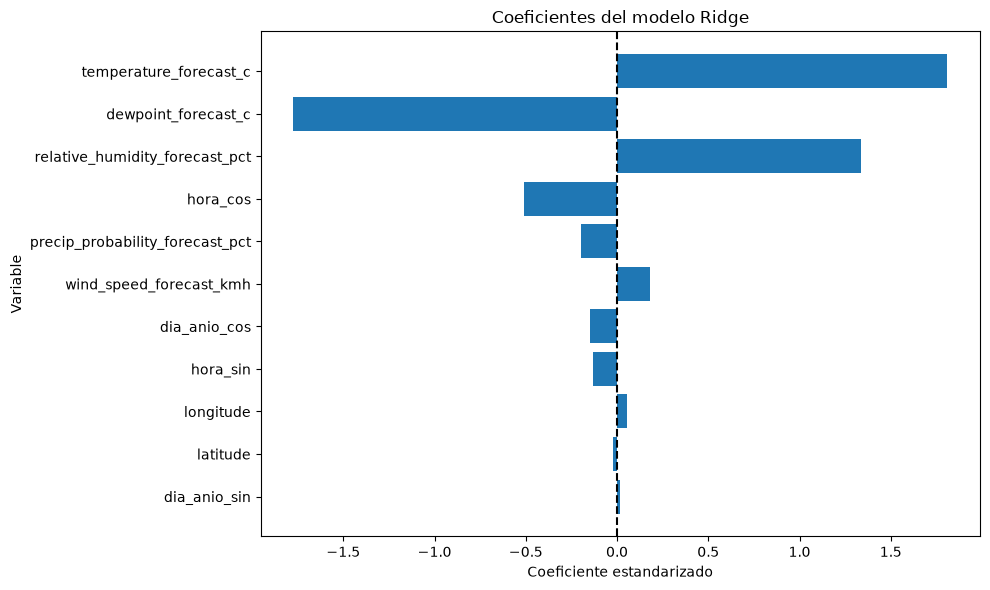

In [18]:

# ==========================================
# CELDA 15 - COEFICIENTES DEL MODELO RIDGE
# ==========================================

# Obtener los coeficientes del modelo entrenado
coeficientes = modelo_ridge.named_steps["modelo"].coef_

# Asociar cada coeficiente a su variable
df_coeficientes = pd.DataFrame({
    "Variable": COLUMNAS_PREDICTORAS,
    "Coeficiente": coeficientes
})

# Ordenar por magnitud absoluta
df_coeficientes["Magnitud"] = (
    df_coeficientes["Coeficiente"].abs()
)

df_coeficientes = df_coeficientes.sort_values(
    "Magnitud",
    ascending=False
)

display(df_coeficientes.round(4))

# Gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    df_coeficientes["Variable"],
    df_coeficientes["Coeficiente"]
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Coeficiente estandarizado")
plt.ylabel("Variable")
plt.title("Coeficientes del modelo Ridge")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


,registros,mae_original,mae_ridge,sesgo_original,sesgo_ridge
fecha,,,,,
2026-10-12,9618,1.4960,1.4226,-0.5298,-0.4244
2026-10-13,9395,1.4204,1.3642,0.0714,0.2054
2026-10-14,9900,1.5336,1.5432,-0.0386,0.1733
2026-10-15,9735,1.3843,1.3852,0.5373,0.8142
2026-10-16,9634,1.4851,1.4718,0.0560,0.2454
2026-10-17,9775,1.2901,1.2133,0.3139,0.3872
2026-10-18,9999,1.4097,1.3764,0.5378,0.7820
2026-10-19,8077,1.8035,1.7216,-0.0967,0.0958
2026-10-20,8196,1.7988,1.7938,-0.0306,-0.0202


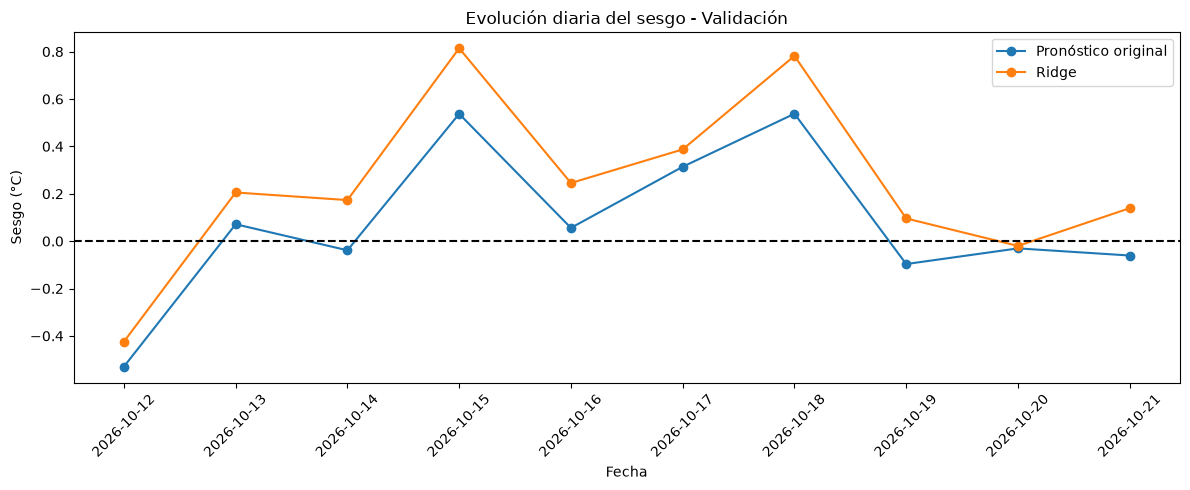

In [19]:

# ==========================================
# CELDA 16 - ERROR DIARIO EN VALIDACION
# ==========================================

df_validacion = df_modelo.loc[
    mask_val,
    ["target_time_utc", "station_id"]
].copy()

df_validacion["error_original"] = y_val.to_numpy()

df_validacion["error_ridge"] = (
    error_residual_ridge_val
)

df_validacion["fecha"] = (
    df_validacion["target_time_utc"].dt.date
)

# Calcular métricas diarias
resumen_diario = (
    df_validacion
    .groupby("fecha")
    .agg(
        registros=("error_original", "size"),
        mae_original=(
            "error_original",
            lambda x: x.abs().mean()
        ),
        mae_ridge=(
            "error_ridge",
            lambda x: x.abs().mean()
        ),
        sesgo_original=("error_original", "mean"),
        sesgo_ridge=("error_ridge", "mean")
    )
)

display(resumen_diario.round(4))

# Comparación visual del sesgo
plt.figure(figsize=(12, 5))

plt.plot(
    resumen_diario.index,
    resumen_diario["sesgo_original"],
    marker="o",
    label="Pronóstico original"
)

plt.plot(
    resumen_diario.index,
    resumen_diario["sesgo_ridge"],
    marker="o",
    label="Ridge"
)

plt.axhline(0, color="black", linestyle="--")

plt.title("Evolución diaria del sesgo - Validación")
plt.xlabel("Fecha")
plt.ylabel("Sesgo (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 6. Interpretación de Ridge y estabilidad temporal

#### Análisis de coeficientes

Los coeficientes estandarizados del modelo Ridge muestran
que la temperatura pronosticada, el punto de rocío y la
humedad relativa presentan las mayores magnitudes.

Estas variables están relacionadas entre sí, por lo que
sus coeficientes pueden verse afectados por
multicolinealidad. En consecuencia, sus magnitudes no
deben interpretarse directamente como importancia
predictiva ni como relaciones causales.

La componente cíclica `hora_cos` también presenta una
asociación relevante con la corrección estimada.

#### Evolución diaria del error

El análisis temporal del conjunto de validación mostró
que Ridge redujo el MAE en 8 de los 10 días evaluados.

Sin embargo, el sesgo residual fue mayor que el original
en todos los días, indicando un desplazamiento sistemático
hacia la subestimación de la temperatura.

En términos globales, Ridge redujo el MAE de 1,5403 °C
a 1,4986 °C, equivalente a una mejora relativa del 2,71 %.

En cambio, el sesgo aumentó de +0,0829 °C a +0,2491 °C.

#### Conclusión

Ridge constituye un primer modelo interpretable que
consigue mejorar moderadamente la precisión del pronóstico.

No obstante, presenta limitaciones para capturar relaciones
no lineales y corregir el sesgo direccional.

Se propone comparar estos resultados con un modelo
Gradient Boosting, capaz de representar relaciones más
complejas entre las condiciones meteorológicas y el error.

La comparación se realizará utilizando el mismo conjunto
de validación y las mismas métricas.


## 7. Gradient Boosting

Vamos a entrenar nuestro segundo modelo, orientado a minimizar el error.
Utilizaremos **HistGradientBoostingRegressor**, que permite aprender relaciones no lineales entre las variables.
A diferencia de **Ridge**, este modelo puede aprender reglas más complejas. Por ejemplo, que la corrección de temperatura dependa de combinaciones específicas de **humedad**, **temperatura** y **hora del día**

In [20]:

# ==========================================
# CELDA 17 - HIST GRADIENT BOOSTING
# ==========================================

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

# Definición del modelo
modelo_hgb = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=150,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42
)

# Entrenamiento
modelo_hgb.fit(X_train, y_train)

# Predicción de la corrección
correccion_hgb_val = modelo_hgb.predict(X_val)

# Error residual
error_residual_hgb_val = (
    y_val.to_numpy() - correccion_hgb_val
)

# Métricas
mae_hgb = np.mean(np.abs(error_residual_hgb_val))
rmse_hgb = np.sqrt(
    np.mean(error_residual_hgb_val ** 2)
)
sesgo_hgb = np.mean(error_residual_hgb_val)

# Mejora sobre el pronóstico original
mejora_hgb = (
    1 - mae_hgb / mae_original_val
) * 100

print("MAE Gradient Boosting:", round(mae_hgb, 4))
print("RMSE Gradient Boosting:", round(rmse_hgb, 4))
print("Sesgo Gradient Boosting:", round(sesgo_hgb, 4))
print("Mejora relativa:", round(mejora_hgb, 2), "%")


MAE Gradient Boosting: 1.4403
RMSE Gradient Boosting: 1.8125
Sesgo Gradient Boosting: 0.0704
Mejora relativa: 6.49 %


In [21]:

# ==========================================
# CELDA 18 - COMPARACION DE MODELOS
# ==========================================

errores_modelos = {
    "Pronóstico original": y_val.to_numpy(),
    "Corrección constante": (
        y_val.to_numpy() - correccion_media
    ),
    "Ridge": error_residual_ridge_val,
    "Gradient Boosting": error_residual_hgb_val
}

comparacion = []

for nombre, residuales in errores_modelos.items():

    mae = np.mean(np.abs(residuales))

    comparacion.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": np.sqrt(np.mean(residuales ** 2)),
        "Sesgo": np.mean(residuales),
        "Mejora MAE (%)": (
            1 - mae / mae_original_val
        ) * 100
    })

tabla_comparacion = pd.DataFrame(comparacion)

display(tabla_comparacion.round(4))


,Modelo,MAE,RMSE,Sesgo,Mejora MAE (%)
0,Pronóstico original,1.5403,1.9336,0.0829,0.0000
1,Corrección constante,1.5387,1.9322,0.0362,0.1018
2,Ridge,1.4986,1.8674,0.2491,2.7107
3,Gradient Boosting,1.4403,1.8125,0.0704,6.4944



### 7. Segundo modelo: Gradient Boosting

Se entrenó un modelo `HistGradientBoostingRegressor` para
predecir el error de temperatura a partir de las mismas
11 variables utilizadas en Ridge.

A diferencia del modelo lineal, Gradient Boosting permite
representar relaciones no lineales e interacciones entre
variables meteorológicas, temporales y geográficas.

Se utilizó una configuración inicial de hiperparámetros,
sin optimización, y se mantuvo la misma división temporal.

#### Comparación en validación

| Modelo | MAE (°C) | RMSE (°C) | Sesgo (°C) |
|---|---:|---:|---:|
| Pronóstico original | 1,5403 | 1,9336 | +0,0829 |
| Corrección constante | 1,5387 | 1,9322 | +0,0362 |
| Ridge | 1,4986 | 1,8674 | +0,2491 |
| Gradient Boosting | 1,4403 | 1,8125 | +0,0704 |

#### Interpretación

Gradient Boosting consiguió reducir el MAE un 6,49 %
y el RMSE aproximadamente un 6,26 % respecto del
pronóstico original.

Además, presentó un sesgo residual de +0,0704 °C,
inferior al del pronóstico original y al de Ridge.

Estos resultados sugieren que el modelo no lineal
consigue aprovechar mejor las relaciones entre las
variables predictoras y el error meteorológico.

#### Conclusión

Gradient Boosting es el modelo inicial con mejor
desempeño global en el conjunto de validación.

No obstante, es necesario evaluar la estabilidad diaria
de sus resultados, analizar la importancia de las
variables y optimizar sus hiperparámetros.

El conjunto de prueba se mantiene reservado para
la evaluación final del modelo seleccionado.


In [22]:

# ==========================================
# CELDA 19 - COMPARACION DIARIA DE MODELOS
# ==========================================

df_comparacion_diaria = pd.DataFrame({
    "fecha": (
        df_modelo.loc[mask_val, "target_time_utc"]
        .dt.date.to_numpy()
    ),
    "error_original": y_val.to_numpy(),
    "error_ridge": error_residual_ridge_val,
    "error_hgb": error_residual_hgb_val
})

# Calcular métricas diarias
comparacion_diaria = (
    df_comparacion_diaria
    .groupby("fecha")
    .agg(
        registros=("error_original", "size"),
        mae_original=(
            "error_original",
            lambda x: x.abs().mean()
        ),
        mae_ridge=(
            "error_ridge",
            lambda x: x.abs().mean()
        ),
        mae_hgb=(
            "error_hgb",
            lambda x: x.abs().mean()
        ),
        sesgo_hgb=("error_hgb", "mean")
    )
)

# Mejora porcentual de Gradient Boosting
comparacion_diaria["mejora_hgb_pct"] = (
    1
    - comparacion_diaria["mae_hgb"]
    / comparacion_diaria["mae_original"]
) * 100

display(comparacion_diaria.round(4))

# Contar días donde mejora cada modelo
dias_ridge = (
    comparacion_diaria["mae_ridge"]
    < comparacion_diaria["mae_original"]
).sum()

dias_hgb = (
    comparacion_diaria["mae_hgb"]
    < comparacion_diaria["mae_original"]
).sum()

print("Días donde Ridge mejora:", dias_ridge)
print("Días donde Gradient Boosting mejora:", dias_hgb)


,registros,mae_original,mae_ridge,mae_hgb,sesgo_hgb,mejora_hgb_pct
fecha,,,,,,
2026-10-12,9618,1.4960,1.4226,1.6355,-0.7504,-9.3217
2026-10-13,9395,1.4204,1.3642,1.3656,-0.0470,3.8620
2026-10-14,9900,1.5336,1.5432,1.5185,-0.0507,0.9846
2026-10-15,9735,1.3843,1.3852,1.1958,0.5468,13.6133
2026-10-16,9634,1.4851,1.4718,1.3248,0.0124,10.7918
2026-10-17,9775,1.2901,1.2133,1.1703,0.1347,9.2880
2026-10-18,9999,1.4097,1.3764,1.3209,0.7212,6.3015
2026-10-19,8077,1.8035,1.7216,1.5284,0.1293,15.2542
2026-10-20,8196,1.7988,1.7938,1.6849,0.0721,6.3334


Días donde Ridge mejora: 8
Días donde Gradient Boosting mejora: 9


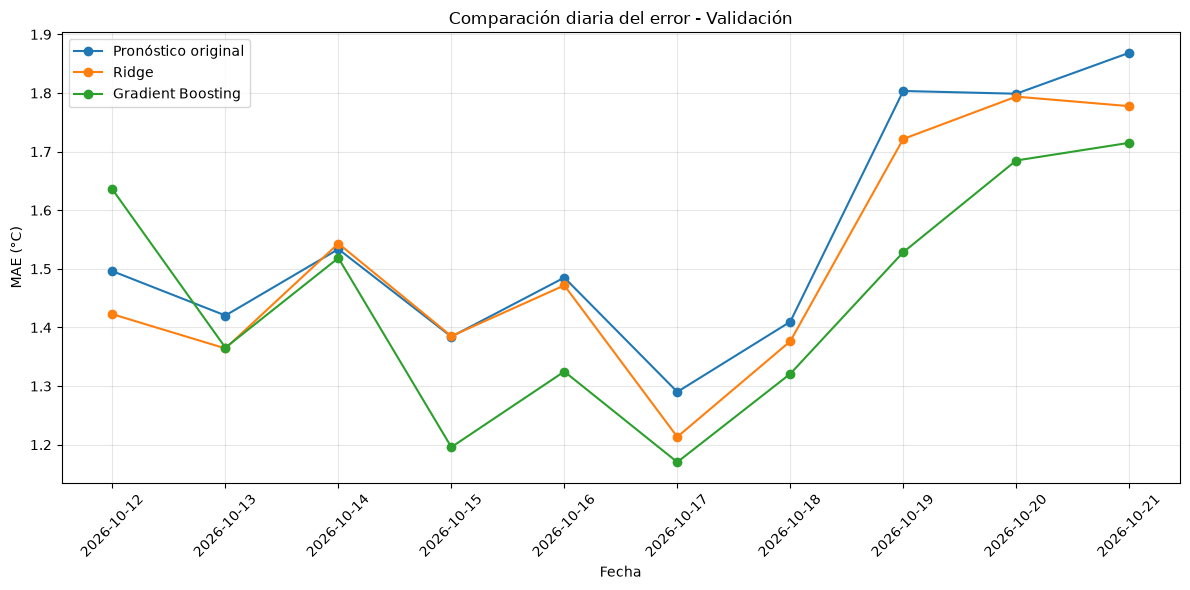

In [23]:

# ==========================================
# CELDA 20 - GRAFICO DE MAE DIARIO
# ==========================================

plt.figure(figsize=(12, 6))

plt.plot(
    comparacion_diaria.index,
    comparacion_diaria["mae_original"],
    marker="o",
    label="Pronóstico original"
)

plt.plot(
    comparacion_diaria.index,
    comparacion_diaria["mae_ridge"],
    marker="o",
    label="Ridge"
)

plt.plot(
    comparacion_diaria.index,
    comparacion_diaria["mae_hgb"],
    marker="o",
    label="Gradient Boosting"
)

plt.xlabel("Fecha")
plt.ylabel("MAE (°C)")
plt.title("Comparación diaria del error - Validación")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 7. Análisis de estabilidad temporal de los modelos

Se evaluó el comportamiento diario de Ridge y Gradient
Boosting durante los diez días del conjunto de validación.

El objetivo fue determinar si la reducción global del
error se mantiene a lo largo del tiempo o si depende
de determinados días.

#### Resultados

| Indicador | Ridge | Gradient Boosting |
|---|---:|---:|
| Días con mejora | 8/10 | 9/10 |
| MAE global | 1,4986 °C | 1,4403 °C |
| Mejora relativa | 2,71 % | 6,49 % |
| Sesgo global | +0,2491 °C | +0,0704 °C |

#### Interpretación

Gradient Boosting redujo el MAE respecto del pronóstico
original en 9 de los 10 días analizados, mostrando
un comportamiento más favorable que Ridge.

La mayor mejora se registró el 19 de octubre, con
una reducción del MAE del 15,25 %.

Sin embargo, el 12 de octubre presentó un
empeoramiento del 9,32 %, acompañado de un
sesgo residual de -0,7504 °C.

Estos resultados muestran que la mejora predictiva
no es uniforme y que existen situaciones en las
cuales la corrección aprendida puede perjudicar
el pronóstico original.

#### Conclusión

Gradient Boosting presenta el mejor desempeño
global y diario entre los modelos evaluados.

Se selecciona como candidato principal para
la optimización de hiperparámetros.

Antes de optimizarlo se analizará la importancia
de las variables predictoras y las posibles
limitaciones del modelo.

Los resultados corresponden al período de validación,
por lo que todavía no permiten establecer su
rendimiento definitivo sobre datos no utilizados
durante la selección del modelo.


,Variable,Importancia_MAE,Desvio
8,hora_cos,0.1449,0.0033
7,hora_sin,0.0874,0.0030
5,wind_speed_forecast_kmh,0.0534,0.0019
6,precip_probability_forecast_pct,0.0332,0.0006
1,longitude,0.0086,0.0004
0,latitude,0.0071,0.0013
3,relative_humidity_forecast_pct,0.0054,0.0039
4,dewpoint_forecast_c,0.0019,0.0009
2,temperature_forecast_c,0.0014,0.0015
10,dia_anio_cos,0.0000,0.0000


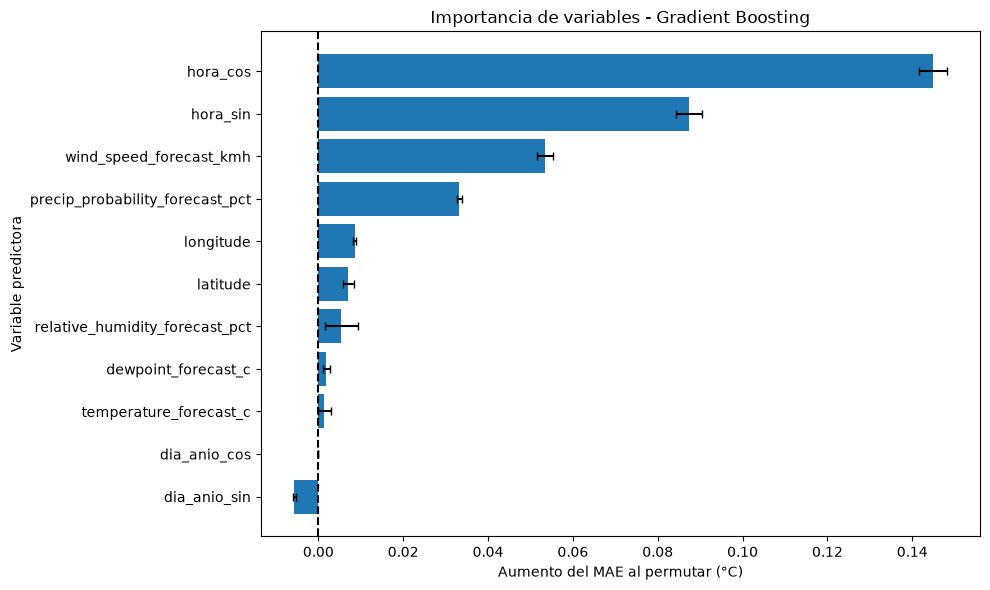

In [24]:

# ==========================================
# CELDA 21 - IMPORTANCIA POR PERMUTACION
# ==========================================

from sklearn.inspection import permutation_importance

# Utilizar una muestra de validación para reducir
# el tiempo de cálculo
X_muestra = X_val.sample(
    n=min(10000, len(X_val)),
    random_state=42
)

# Conservar la correspondencia con el objetivo
y_muestra = y_val.loc[X_muestra.index]

# Calcular importancia por permutación
importancias = permutation_importance(
    modelo_hgb,
    X_muestra,
    y_muestra,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# Organizar resultados
df_importancias = pd.DataFrame({
    "Variable": COLUMNAS_PREDICTORAS,
    "Importancia_MAE": importancias.importances_mean,
    "Desvio": importancias.importances_std
})

df_importancias = df_importancias.sort_values(
    "Importancia_MAE",
    ascending=False
)

display(df_importancias.round(4))

# Gráfico de importancia
plt.figure(figsize=(10, 6))

plt.barh(
    df_importancias["Variable"],
    df_importancias["Importancia_MAE"],
    xerr=df_importancias["Desvio"],
    capsize=3
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Aumento del MAE al permutar (°C)")
plt.ylabel("Variable predictora")
plt.title("Importancia de variables - Gradient Boosting")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



### 10. Interpretabilidad de Gradient Boosting

Se utilizó importancia por permutación para estudiar qué
variables contribuyen al desempeño predictivo del modelo
Gradient Boosting.

El procedimiento consiste en desordenar una variable
predictora y medir cuánto aumenta el MAE del modelo.

Se utilizó una muestra de 10.000 registros del conjunto
de validación y tres repeticiones por variable.

#### Resultados principales

| Variable | Importancia MAE (°C) |
|---|---:|
| Hora (coseno) | +0,1449 |
| Hora (seno) | +0,0874 |
| Velocidad del viento | +0,0534 |
| Probabilidad de precipitación | +0,0332 |
| Longitud | +0,0086 |
| Latitud | +0,0071 |
| Humedad relativa | +0,0054 |
| Punto de rocío | +0,0019 |
| Temperatura pronosticada | +0,0014 |
| Día del año (coseno) | 0,0000 |
| Día del año (seno) | −0,0056 |

#### Interpretación

Las variables temporales relacionadas con la hora del día
presentaron las mayores importancias individuales.

Esto sugiere que el modelo utiliza patrones horarios
para estimar las correcciones de temperatura.

La velocidad del viento y la probabilidad de precipitación
también mostraron una contribución predictiva relevante.

Por otra parte, la temperatura, la humedad y el punto
de rocío tuvieron importancias individuales reducidas.
Esto podría estar relacionado con la correlación existente
entre estas variables.

La variable `dia_anio_sin` presentó importancia negativa,
lo que indica que su permutación redujo ligeramente el
error en la muestra analizada.

Este resultado podría reflejar patrones temporales poco
generalizables o redundancia entre variables.

#### Limitaciones

La importancia por permutación mide la dependencia
predictiva del modelo respecto de cada variable,
pero no demuestra relaciones causales.

Además, la correlación entre predictores puede alterar
las importancias individuales.

Por este motivo, se realizará una evaluación por grupos
de variables relacionadas antes de modificar los
atributos del modelo.


In [25]:

# ==========================================
# CELDA 22 - IMPORTANCIA AGRUPADA
# ==========================================

rng = np.random.default_rng(42)

# Muestra reproducible de validación
X_muestra = X_val.sample(
    n=min(10000, len(X_val)),
    random_state=42
)

y_muestra = y_val.loc[X_muestra.index].to_numpy()

# MAE de referencia
pred_base = modelo_hgb.predict(X_muestra)

mae_base = np.mean(
    np.abs(y_muestra - pred_base)
)

# Grupos de variables relacionadas
GRUPOS = {
    "Hora UTC": ["hora_sin", "hora_cos"],
    "Día del año": ["dia_anio_sin", "dia_anio_cos"],
    "Condiciones térmicas": [
        "temperature_forecast_c",
        "relative_humidity_forecast_pct",
        "dewpoint_forecast_c"
    ],
    "Ubicación": ["latitude", "longitude"],
    "Viento": ["wind_speed_forecast_kmh"],
    "Precipitación": ["precip_probability_forecast_pct"]
}

resultados_grupos = []

for nombre, columnas in GRUPOS.items():

    aumentos = []

    for repeticion in range(5):

        X_permutado = X_muestra.copy()

        # Misma permutación para todas las
        # variables del grupo
        indices = rng.permutation(len(X_muestra))

        X_permutado[columnas] = (
            X_muestra[columnas].to_numpy()[indices]
        )

        pred = modelo_hgb.predict(X_permutado)

        mae_permutado = np.mean(
            np.abs(y_muestra - pred)
        )

        aumentos.append(
            mae_permutado - mae_base
        )

    resultados_grupos.append({
        "Grupo": nombre,
        "Aumento_MAE": np.mean(aumentos),
        "Desvio": np.std(aumentos)
    })

tabla_grupos = (
    pd.DataFrame(resultados_grupos)
    .sort_values("Aumento_MAE", ascending=False)
)

print("MAE de referencia:", round(mae_base, 4))

display(tabla_grupos.round(4))


MAE de referencia: 1.4333


,Grupo,Aumento_MAE,Desvio
0,Hora UTC,0.2135,0.0052
4,Viento,0.0562,0.0016
5,Precipitación,0.0334,0.0014
2,Condiciones térmicas,0.0082,0.0048
3,Ubicación,0.0005,0.0010
1,Día del año,-0.0069,0.0013



### 11. Importancia agrupada de variables predictoras

Para complementar la importancia individual, se realizó
una evaluación por grupos de variables relacionadas.

Se aplicó una misma permutación a las variables de cada
grupo, conservando las relaciones internas entre ellas.

#### Resultados

| Grupo | Aumento del MAE (°C) |
|---|---:|
| Hora UTC | +0,2135 |
| Viento | +0,0562 |
| Precipitación | +0,0334 |
| Condiciones térmicas | +0,0082 |
| Ubicación | +0,0005 |
| Día del año | -0,0069 |

#### Interpretación

El grupo de variables horarias presentó la mayor
importancia predictiva, seguido por la velocidad del
viento y la probabilidad de precipitación.

Estos resultados sugieren que Gradient Boosting utiliza
principalmente patrones horarios y condiciones
meteorológicas para estimar las correcciones.

Las variables correspondientes al día del año presentaron
una importancia negativa, lo que indica que su
permutación redujo ligeramente el error del modelo.

Dado que el período estudiado abarca solamente 53 días,
es posible que estas variables estén representando
patrones temporales que no generalizan correctamente.

Sin embargo, la importancia por permutación no demuestra
que eliminar dichas variables mejore el rendimiento.

Por este motivo, se propone realizar un experimento
de ablación: entrenar nuevamente el modelo sin las
variables del día del año y comparar las métricas de
validación.

La selección definitiva deberá considerar tanto el
rendimiento promedio como su estabilidad temporal.


In [26]:

# ==========================================
# CELDA 23 - EXPERIMENTO DE ABLACION
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# 1. Seleccionar variables sin día del año
COLUMNAS_SIN_DIA = [
    columna
    for columna in COLUMNAS_PREDICTORAS
    if columna not in [
        "dia_anio_sin",
        "dia_anio_cos"
    ]
]

print("Variables originales:", len(COLUMNAS_PREDICTORAS))
print("Variables nuevas:", len(COLUMNAS_SIN_DIA))

# 2. Preparar conjuntos
X_train_sin_dia = X_train[COLUMNAS_SIN_DIA].copy()
X_val_sin_dia = X_val[COLUMNAS_SIN_DIA].copy()

# 3. Crear una copia del modelo original
# Mantiene exactamente los hiperparámetros
modelo_hgb_sin_dia = clone(modelo_hgb)

# 4. Entrenar desde cero
modelo_hgb_sin_dia.fit(
    X_train_sin_dia,
    y_train
)

# 5. Predecir correcciones
correccion_sin_dia = modelo_hgb_sin_dia.predict(
    X_val_sin_dia
)

# 6. Calcular errores residuales
error_residual_sin_dia = (
    y_val.to_numpy() - correccion_sin_dia
)

# 7. Comparar contra el modelo original
resultados_ablacion = []

modelos_comparar = {
    "Pronóstico original": y_val.to_numpy(),
    "HGB completo": error_residual_hgb_val,
    "HGB sin día del año": error_residual_sin_dia
}

for nombre, errores in modelos_comparar.items():

    mae = np.mean(np.abs(errores))
    rmse = np.sqrt(np.mean(errores ** 2))
    sesgo = np.mean(errores)

    resultados_ablacion.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "Sesgo": sesgo,
        "Mejora vs original (%)": (
            1 - mae / mae_original_val
        ) * 100
    })

tabla_ablacion = pd.DataFrame(resultados_ablacion)

display(tabla_ablacion.round(4))


Variables originales: 11
Variables nuevas: 9


,Modelo,MAE,RMSE,Sesgo,Mejora vs original (%)
0,Pronóstico original,1.5403,1.9336,0.0829,0.0000
1,HGB completo,1.4403,1.8125,0.0704,6.4944
2,HGB sin día del año,1.3671,1.7433,-0.0838,11.2452


,original,hgb_completo,hgb_sin_dia,diferencia
fecha,,,,
2026-10-12,1.4960,1.6355,1.5423,-0.0932
2026-10-13,1.4204,1.3656,1.2568,-0.1088
2026-10-14,1.5336,1.5185,1.4503,-0.0682
2026-10-15,1.3843,1.1958,1.1551,-0.0407
2026-10-16,1.4851,1.3248,1.3530,0.0282
2026-10-17,1.2901,1.1703,1.1367,-0.0336
2026-10-18,1.4097,1.3209,1.2375,-0.0834
2026-10-19,1.8035,1.5284,1.4752,-0.0532
2026-10-20,1.7988,1.6849,1.5811,-0.1037


Días donde mejora el modelo sin día del año: 9 de 10


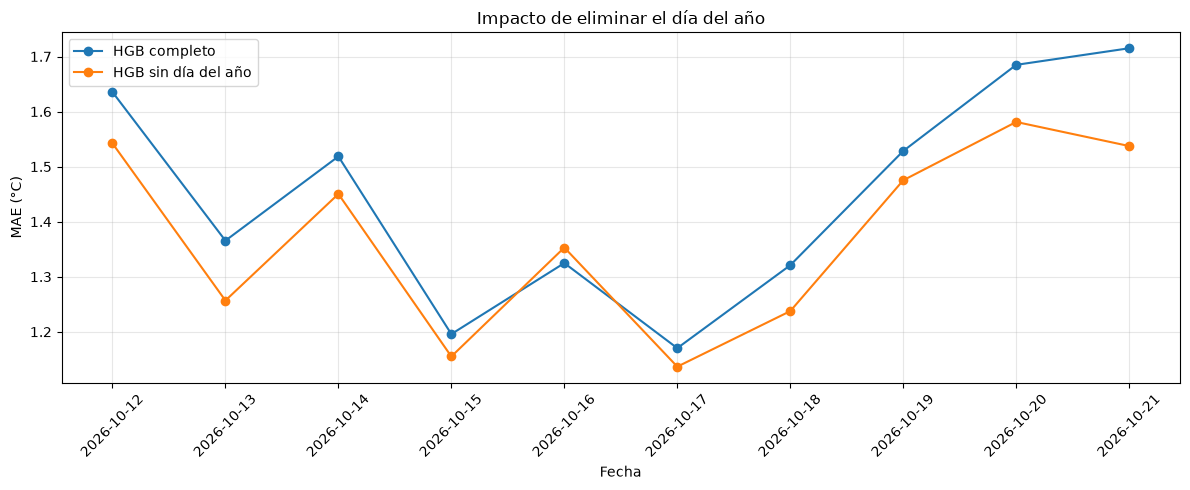

In [27]:

# ==========================================
# CELDA 24 - ESTABILIDAD DE LA ABLACION
# ==========================================

df_ablacion_diaria = pd.DataFrame({
    "fecha": (
        df_modelo.loc[mask_val, "target_time_utc"]
        .dt.date.to_numpy()
    ),
    "original": np.abs(y_val.to_numpy()),
    "hgb_completo": np.abs(error_residual_hgb_val),
    "hgb_sin_dia": np.abs(error_residual_sin_dia)
})

# MAE diario por modelo
mae_diario_ablacion = (
    df_ablacion_diaria
    .groupby("fecha")
    [["original", "hgb_completo", "hgb_sin_dia"]]
    .mean()
)

# Diferencia respecto del modelo completo
mae_diario_ablacion["diferencia"] = (
    mae_diario_ablacion["hgb_sin_dia"]
    - mae_diario_ablacion["hgb_completo"]
)

display(mae_diario_ablacion.round(4))

# Cantidad de días donde la versión simplificada
# supera al modelo completo
dias_mejora = (
    mae_diario_ablacion["diferencia"] < 0
).sum()

print(
    "Días donde mejora el modelo sin día del año:",
    dias_mejora,
    "de",
    len(mae_diario_ablacion)
)

# Gráfico comparativo
plt.figure(figsize=(12, 5))

plt.plot(
    mae_diario_ablacion.index,
    mae_diario_ablacion["hgb_completo"],
    marker="o",
    label="HGB completo"
)

plt.plot(
    mae_diario_ablacion.index,
    mae_diario_ablacion["hgb_sin_dia"],
    marker="o",
    label="HGB sin día del año"
)

plt.xlabel("Fecha")
plt.ylabel("MAE (°C)")
plt.title("Impacto de eliminar el día del año")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



### 12. Experimento de ablación: eliminación del día del año

Se realizó un experimento de ablación para determinar
si las variables `dia_anio_sin` y `dia_anio_cos`
mejoraban el desempeño de Gradient Boosting.

Se entrenó nuevamente el modelo utilizando 9 variables
predictoras, manteniendo los mismos hiperparámetros,
registros de entrenamiento y período de validación.

#### Comparación de resultados

| Métrica | HGB completo | HGB sin día |
|---|---:|---:|
| Variables predictoras | 11 | 9 |
| MAE (°C) | 1,4403 | 1,3671 |
| RMSE (°C) | 1,8125 | 1,7433 |
| Sesgo (°C) | +0,0704 | -0,0838 |
| Mejora vs. original | 6,49 % | 11,25 % |

#### Interpretación

La eliminación de las variables del día del año redujo
el MAE aproximadamente un 5,08 % respecto del modelo
Gradient Boosting completo.

La mejora se observó en 9 de los 10 días de validación.

Estos resultados sugieren que las variables eliminadas
podrían estar introduciendo patrones temporales poco
generalizables.

El período analizado comprende solamente 53 días
consecutivos, lo que limita la posibilidad de aprender
relaciones estacionales anuales.

Sin embargo, la eliminación de dichas variables produjo
un cambio en el sesgo residual, que pasó de +0,0704 °C
a -0,0838 °C.

Además, el modelo simplificado todavía presentó un
rendimiento inferior al pronóstico original el 12 de octubre.

#### Conclusión

La versión de Gradient Boosting con 9 variables presenta
mejor rendimiento global en el conjunto de validación.

Se considera el candidato principal para continuar el
modelado, aunque todavía es necesario verificar que la
mejora se mantenga en otros períodos temporales.

Por este motivo, antes de optimizar hiperparámetros,
se propone realizar una validación temporal expansiva
utilizando exclusivamente el conjunto de entrenamiento.


In [28]:

# ==========================================
# CELDA 25 - VALIDACION TEMPORAL EXPANSIVA
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# Fechas correspondientes al conjunto de entrenamiento
fechas_train = (
    df_modelo.loc[X_train.index, "target_time_utc"]
    .dt.normalize()
)

# Cada fold utiliza fechas anteriores para entrenar
# y deja un día de separación antes de validar.
FOLDS = [
    ("2026-09-20", "2026-09-22", "2026-09-26"),
    ("2026-09-26", "2026-09-28", "2026-10-02"),
    ("2026-10-02", "2026-10-04", "2026-10-10")
]

resultados_cv = []

for i, (fin_train, inicio_val, fin_val) in enumerate(FOLDS, 1):

    fin_train = pd.Timestamp(fin_train, tz="UTC")
    inicio_val = pd.Timestamp(inicio_val, tz="UTC")
    fin_val = pd.Timestamp(fin_val, tz="UTC")

    mask_entrenamiento = fechas_train <= fin_train

    mask_validacion = (
        (fechas_train >= inicio_val)
        & (fechas_train <= fin_val)
    )

    # Entrenamiento y validación de este fold
    X_ent = X_train.loc[mask_entrenamiento]
    y_ent = y_train.loc[mask_entrenamiento]

    X_eval = X_train.loc[mask_validacion]
    y_eval = y_train.loc[mask_validacion]

    # Modelos con idénticos hiperparámetros
    completo = clone(modelo_hgb)
    reducido = clone(modelo_hgb)

    # Entrenar modelo completo
    completo.fit(X_ent, y_ent)

    # Entrenar modelo sin día del año
    reducido.fit(
        X_ent[COLUMNAS_SIN_DIA],
        y_ent
    )

    # Predecir en fechas futuras
    pred_completo = completo.predict(X_eval)

    pred_reducido = reducido.predict(
        X_eval[COLUMNAS_SIN_DIA]
    )

    # Calcular MAE
    mae_original = np.abs(y_eval.to_numpy()).mean()

    mae_completo = np.mean(
        np.abs(y_eval.to_numpy() - pred_completo)
    )

    mae_reducido = np.mean(
        np.abs(y_eval.to_numpy() - pred_reducido)
    )

    resultados_cv.append({
        "Fold": i,
        "Registros_validacion": len(y_eval),
        "MAE_original": mae_original,
        "MAE_completo": mae_completo,
        "MAE_sin_dia": mae_reducido,
        "Diferencia_MAE": mae_reducido - mae_completo
    })

# Tabla de resultados
tabla_cv = pd.DataFrame(resultados_cv)

display(tabla_cv.round(4))

print(
    "Folds donde mejora el modelo simplificado:",
    (tabla_cv["Diferencia_MAE"] < 0).sum(),
    "de",
    len(tabla_cv)
)

print("\nPromedio de MAE por modelo:")
display(
    tabla_cv[
        ["MAE_original", "MAE_completo", "MAE_sin_dia"]
    ].mean().round(4)
)


,Fold,Registros_validacion,MAE_original,MAE_completo,MAE_sin_dia,Diferencia_MAE
0,1,41279,1.4514,1.5196,1.4326,-0.0870
1,2,45812,1.4564,1.3490,1.3134,-0.0356
2,3,67642,1.5092,1.3206,1.3300,0.0094


Folds donde mejora el modelo simplificado: 2 de 3

Promedio de MAE por modelo:


MAE_original    1.4723
MAE_completo    1.3964
MAE_sin_dia     1.3587
dtype: float64


### 13. Validación temporal expansiva

Se realizó una validación temporal expansiva para comparar
los modelos Gradient Boosting de 11 y 9 variables en
diferentes períodos cronológicos.

Se utilizaron tres folds, entrenando exclusivamente
con información anterior a cada período de validación.

Entre entrenamiento y validación se dejó una separación
temporal de un día.

#### Resultados

| Fold | MAE original | HGB completo | HGB sin día |
|---|---:|---:|---:|
| 1 | 1,4514 | 1,5196 | 1,4326 |
| 2 | 1,4564 | 1,3490 | 1,3134 |
| 3 | 1,5092 | 1,3206 | 1,3300 |
| Promedio | 1,4723 | 1,3964 | 1,3587 |

#### Interpretación

El modelo simplificado obtuvo un MAE promedio de
1,3587 °C, inferior al modelo completo (1,3964 °C).

También redujo el MAE respecto del pronóstico original
en los tres folds evaluados.

La versión de 9 variables superó a la de 11 variables
en dos de los tres períodos. En el tercero, el modelo
completo presentó una ventaja de 0,0094 °C.

La reducción media del MAE respecto del pronóstico
original fue aproximadamente del 7,72 %.

#### Conclusión

Los resultados respaldan la elección de Gradient
Boosting con 9 variables como candidato principal
para continuar el trabajo.

La eliminación del día del año parece mejorar la
generalización temporal durante el período estudiado.

No obstante, estos resultados no garantizan el mismo
desempeño en períodos futuros, especialmente debido
a la duración limitada del dataset.

Se continuará con la optimización de hiperparámetros
utilizando los folds temporales del conjunto de
entrenamiento, sin utilizar el conjunto de prueba.


## Optimizacion de Hiperparametros


In [29]:

# ==========================================
# CELDA 26 - OPTIMIZACION DE HIPERPARAMETROS
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# Configuraciones a comparar
CONFIGURACIONES = [
    {
        "nombre": "Configuración inicial",
        "learning_rate": 0.05,
        "max_iter": 150,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0
    },
    {
        "nombre": "Árboles más simples",
        "learning_rate": 0.05,
        "max_iter": 150,
        "max_leaf_nodes": 7,
        "l2_regularization": 1.0
    },
    {
        "nombre": "Árboles más complejos",
        "learning_rate": 0.05,
        "max_iter": 150,
        "max_leaf_nodes": 31,
        "l2_regularization": 1.0
    },
    {
        "nombre": "Aprendizaje más lento",
        "learning_rate": 0.03,
        "max_iter": 250,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0
    },
    {
        "nombre": "Aprendizaje más rápido",
        "learning_rate": 0.10,
        "max_iter": 100,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0
    },
    {
        "nombre": "Mayor regularización",
        "learning_rate": 0.05,
        "max_iter": 150,
        "max_leaf_nodes": 15,
        "l2_regularization": 10.0
    }
]

# Fechas de entrenamiento
fechas_cv = (
    df_modelo.loc[X_train.index, "target_time_utc"]
    .dt.normalize()
)

resultados_busqueda = []

for config in CONFIGURACIONES:

    puntajes = []

    print("\nEvaluando:", config["nombre"])

    for i, (fin_ent, inicio_val, fin_val) in enumerate(FOLDS, 1):

        fin_ent = pd.Timestamp(fin_ent, tz="UTC")
        inicio_val = pd.Timestamp(inicio_val, tz="UTC")
        fin_val = pd.Timestamp(fin_val, tz="UTC")

        # Separación cronológica
        mask_ent = fechas_cv <= fin_ent

        mask_eval = (
            (fechas_cv >= inicio_val)
            & (fechas_cv <= fin_val)
        )

        # Datos del fold
        X_ent = X_train.loc[
            mask_ent, COLUMNAS_SIN_DIA
        ]
        y_ent = y_train.loc[mask_ent]

        X_eval = X_train.loc[
            mask_eval, COLUMNAS_SIN_DIA
        ]
        y_eval = y_train.loc[mask_eval]

        # Crear modelo con los hiperparámetros
        modelo = clone(modelo_hgb_sin_dia)

        modelo.set_params(
            learning_rate=config["learning_rate"],
            max_iter=config["max_iter"],
            max_leaf_nodes=config["max_leaf_nodes"],
            l2_regularization=config["l2_regularization"]
        )

        # Entrenar
        modelo.fit(X_ent, y_ent)

        # Predecir el error
        pred = modelo.predict(X_eval)

        # MAE de la corrección
        mae = np.mean(
            np.abs(y_eval.to_numpy() - pred)
        )

        puntajes.append(mae)

        print(f"  Fold {i}: MAE = {mae:.4f}")

    resultados_busqueda.append({
        "Configuración": config["nombre"],
        "MAE_CV": np.mean(puntajes),
        "Desvio_CV": np.std(puntajes),
        "Fold_1": puntajes[0],
        "Fold_2": puntajes[1],
        "Fold_3": puntajes[2]
    })

# Tabla de resultados
tabla_busqueda = (
    pd.DataFrame(resultados_busqueda)
    .sort_values("MAE_CV")
    .reset_index(drop=True)
)

display(tabla_busqueda.round(4))



Evaluando: Configuración inicial
  Fold 1: MAE = 1.4326
  Fold 2: MAE = 1.3134
  Fold 3: MAE = 1.3300

Evaluando: Árboles más simples
  Fold 1: MAE = 1.4194
  Fold 2: MAE = 1.3243
  Fold 3: MAE = 1.3394

Evaluando: Árboles más complejos
  Fold 1: MAE = 1.4685
  Fold 2: MAE = 1.3043
  Fold 3: MAE = 1.3192

Evaluando: Aprendizaje más lento
  Fold 1: MAE = 1.4325
  Fold 2: MAE = 1.3136
  Fold 3: MAE = 1.3270

Evaluando: Aprendizaje más rápido
  Fold 1: MAE = 1.4485
  Fold 2: MAE = 1.3093
  Fold 3: MAE = 1.3281

Evaluando: Mayor regularización
  Fold 1: MAE = 1.4301
  Fold 2: MAE = 1.3100
  Fold 3: MAE = 1.3274


,Configuración,MAE_CV,Desvio_CV,Fold_1,Fold_2,Fold_3
0,Mayor regularización,1.3558,0.0530,1.4301,1.3100,1.3274
1,Aprendizaje más lento,1.3577,0.0531,1.4325,1.3136,1.3270
2,Configuración inicial,1.3587,0.0527,1.4326,1.3134,1.3300
3,Árboles más simples,1.3610,0.0417,1.4194,1.3243,1.3394
4,Aprendizaje más rápido,1.3620,0.0616,1.4485,1.3093,1.3281
5,Árboles más complejos,1.3640,0.0741,1.4685,1.3043,1.3192


¿Qué podemos concluir?
1. La mayor regularización obtuvo el mejor promedio.

El MAE bajó de 1,3587 °C a 1,3558 °C, una mejora aproximada de 0,21 % frente a la configuración inicial.

Es una mejora pequeña, especialmente comparada con la variación de rendimiento entre períodos.

2. La mayor regularización mejoró los tres folds.

Aunque las diferencias son reducidas, el modelo con l2_regularization=10.0 superó a la configuración inicial en los tres períodos de validación.

3. Los árboles más complejos no necesariamente funcionan mejor.

La configuración con 31 hojas obtuvo el peor promedio. Esto demuestra que aumentar la complejidad no garantiza mejores predicciones.

4. La eliminación del día del año produjo una mejora mucho mayor que modificar los hiperparámetros.

Este es uno de los hallazgos metodológicos más interesantes de nuestro trabajo: la selección de variables tuvo más impacto que los ajustes evaluados del algoritmo


### 14. Optimización de hiperparámetros

Se realizó una búsqueda acotada de hiperparámetros
sobre el modelo HistGradientBoostingRegressor
con 9 variables predictoras.

Se evaluaron seis configuraciones utilizando tres
folds de validación temporal expansiva.

El criterio principal de selección fue minimizar
el MAE promedio de validación.

#### Resultados

| Configuración | MAE CV (°C) | Desvío |
|---|---:|---:|
| Mayor regularización | 1,3558 | 0,0530 |
| Aprendizaje más lento | 1,3577 | 0,0531 |
| Configuración inicial | 1,3587 | 0,0527 |
| Árboles más simples | 1,3610 | 0,0417 |
| Aprendizaje más rápido | 1,3620 | 0,0616 |
| Árboles más complejos | 1,3640 | 0,0741 |

#### Interpretación

La configuración con mayor regularización presentó
el menor MAE promedio, con un valor de 1,3558 °C.

La mejora respecto de la configuración inicial fue
pequeña, aproximadamente del 0,21 %.

Sin embargo, la configuración seleccionada obtuvo
un MAE inferior al inicial en los tres folds.

Los resultados también muestran que aumentar la
complejidad de los árboles no garantiza una mejora
del rendimiento predictivo.

La variabilidad entre períodos fue considerablemente
mayor que las diferencias entre configuraciones.

#### Configuración seleccionada

- learning_rate: 0.05
- max_iter: 150
- max_leaf_nodes: 15
- l2_regularization: 10.0
- early_stopping: False
- random_state: 42

#### Conclusión

Se seleccionó la configuración con mayor
regularización por presentar el menor MAE promedio
y mejoras consistentes frente a la configuración
inicial en los tres folds.

La mejora obtenida mediante la optimización fue
modesta en comparación con la conseguida al
eliminar las variables del día del año.

Estos resultados destacan la importancia de una
selección adecuada de atributos predictivos.

La configuración seleccionada será evaluada
nuevamente sobre el período de validación externo
antes de realizar la evaluación final.


In [30]:

# ==========================================
# CELDA 27 - MODELO REGULARIZADO
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# Crear una copia del modelo de 9 variables
modelo_hgb_optimizado = clone(modelo_hgb_sin_dia)

# Aplicar hiperparámetros seleccionados
modelo_hgb_optimizado.set_params(
    learning_rate=0.05,
    max_iter=150,
    max_leaf_nodes=15,
    l2_regularization=10.0,
    early_stopping=False,
    random_state=42
)

# Entrenar con todo el conjunto de entrenamiento
modelo_hgb_optimizado.fit(
    X_train_sin_dia,
    y_train
)

# Predecir la corrección en validación
pred_optimizado_val = modelo_hgb_optimizado.predict(
    X_val_sin_dia
)

# Error residual
error_optimizado_val = (
    y_val.to_numpy() - pred_optimizado_val
)

# Comparar configuraciones
errores_comparacion = {
    "Pronóstico original": y_val.to_numpy(),
    "HGB inicial (9 variables)": error_residual_sin_dia,
    "HGB regularizado (9 variables)": error_optimizado_val
}

resultados_optimizacion = []

mae_referencia = np.abs(y_val.to_numpy()).mean()

for nombre, errores in errores_comparacion.items():

    mae = np.mean(np.abs(errores))
    rmse = np.sqrt(np.mean(errores ** 2))
    sesgo = np.mean(errores)

    resultados_optimizacion.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "Sesgo": sesgo,
        "Mejora MAE (%)": (
            1 - mae / mae_referencia
        ) * 100
    })

tabla_optimizacion = pd.DataFrame(
    resultados_optimizacion
)

display(tabla_optimizacion.round(4))


,Modelo,MAE,RMSE,Sesgo,Mejora MAE (%)
0,Pronóstico original,1.5403,1.9336,0.0829,0.0000
1,HGB inicial (9 variables),1.3671,1.7433,-0.0838,11.2452
2,HGB regularizado (9 variables),1.3650,1.7419,-0.0957,11.3838



### 15. Evaluación de la configuración optimizada

Se entrenó nuevamente Gradient Boosting con las 9 variables
seleccionadas y la configuración de mayor regularización,
utilizando exclusivamente el conjunto de entrenamiento.

La evaluación se realizó sobre el período de validación
del 12 al 21 de octubre de 2026.

#### Resultados

| Métrica | HGB inicial | HGB regularizado |
|---|---:|---:|
| MAE (°C) | 1,3671 | 1,3650 |
| RMSE (°C) | 1,7433 | 1,7419 |
| Sesgo (°C) | -0,0838 | -0,0957 |
| Mejora vs. original | 11,25 % | 11,38 % |

#### Interpretación

La configuración regularizada consiguió reducir
ligeramente el MAE y el RMSE respecto del modelo
simplificado inicial.

La reducción del MAE fue de aproximadamente 0,0021 °C,
equivalente a una mejora relativa del 0,15 %.

Sin embargo, el sesgo residual aumentó ligeramente
en valor absoluto, indicando una mayor tendencia
a sobreestimar la temperatura observada.

Las diferencias son pequeñas y no permiten afirmar
que la optimización produzca una mejora sustancial
en el desempeño futuro.

#### Conclusión

Se selecciona provisionalmente el modelo Gradient
Boosting de 9 variables con regularización L2 de 10.0,
por presentar el menor MAE en las evaluaciones realizadas.

Se finaliza la selección de hiperparámetros para evitar
continuar ajustando el modelo sobre los mismos datos
de validación.

El siguiente paso será interpretar el comportamiento
del modelo seleccionado mediante técnicas de
explicabilidad.

Finalmente, se evaluará su capacidad de generalización
utilizando el conjunto de prueba reservado.


## interpretabilidad con SHAP



In [34]:

import shap

print("Versión de SHAP:", shap.__version__)


c:\Users\Jorge\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Versión de SHAP: 0.54.1


In [35]:

# Muestra de validación
X_shap = X_val_sin_dia.sample(
    n=min(500, len(X_val_sin_dia)),
    random_state=42
)

# Crear explicador SHAP
explainer = shap.TreeExplainer(modelo_hgb_optimizado)

# Calcular contribuciones
shap_values = explainer(X_shap)

print("Registros analizados:", len(X_shap))
print("Dimensiones:", shap_values.values.shape)


Registros analizados: 500
Dimensiones: (500, 9)


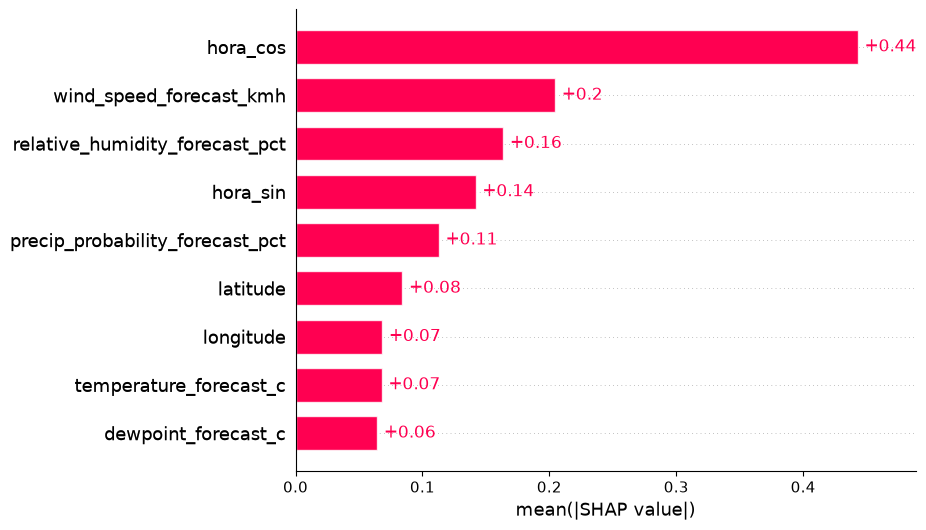

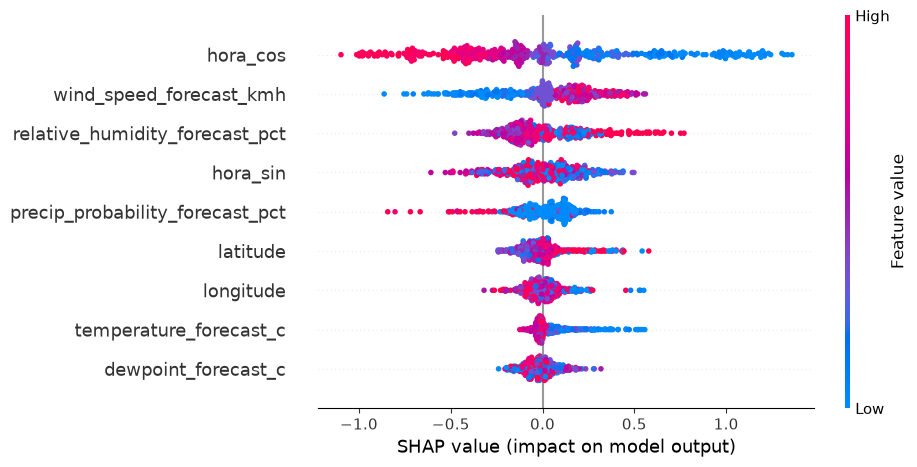

In [36]:

# ==========================================
# CELDA 30 - INTERPRETABILIDAD GLOBAL SHAP
# ==========================================

# Gráfico 1: importancia global de las variables
shap.plots.bar(
    shap_values,
    max_display=9
)

# Gráfico 2: distribución de los efectos SHAP
shap.plots.beeswarm(
    shap_values,
    max_display=9
)


Gráfico Beeswarm

Muestra cómo influyen los valores de cada variable en las correcciones del modelo.
- Eje horizontal: contribución SHAP, expresada en °C.
- Puntos a la derecha: aumentan la corrección estimada.
- Puntos a la izquierda: disminuyen la corrección estimada.
- Color rojo: valores elevados de la variable.
- Color azul: valores bajos de la variable.
Recordá que nuestro modelo predice una corrección de temperatura:
\[
$T_{\text{corregida}}=T_{\text{pronosticada}}+\hat e$
\]

Por lo tanto, una contribución SHAP positiva favorece una corrección hacia arriba

,latitude,longitude,temperature_forecast_c,relative_humidity_forecast_pct,dewpoint_forecast_c,wind_speed_forecast_kmh,precip_probability_forecast_pct,hora_sin,hora_cos
303634,41.3275,-72.04944,17.2222,100.0,17.2222,20.9215,7.0,0.965926,0.258819


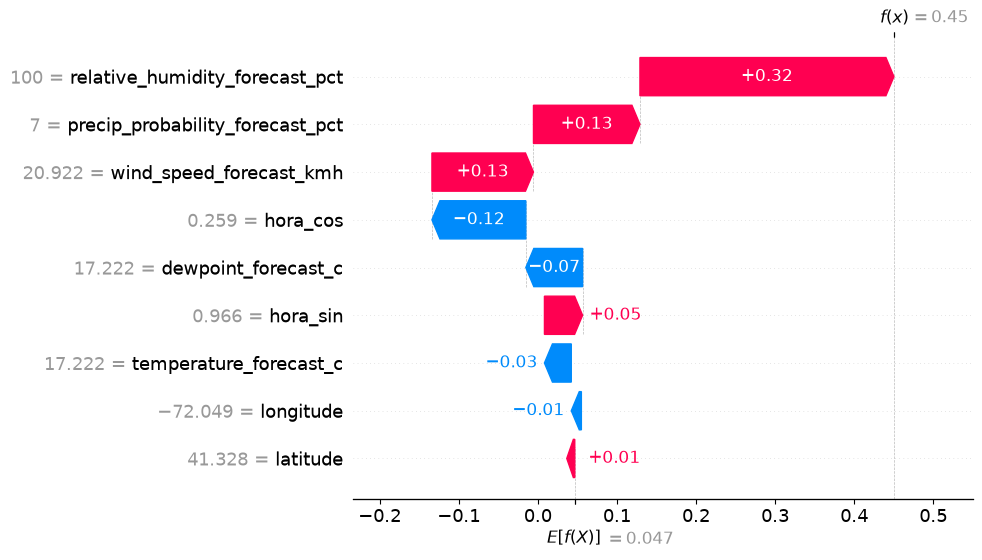

Temperatura pronosticada: 17.22 °C
Corrección estimada: 0.45 °C
Temperatura corregida: 17.67 °C


In [37]:

# ==========================================
# CELDA 31 - EXPLICACION INDIVIDUAL SHAP
# ==========================================

# Seleccionar el primer registro de la muestra
indice = 0

# Mostrar sus variables meteorológicas
display(X_shap.iloc[[indice]])

# Gráfico de explicación individual
shap.plots.waterfall(
    shap_values[indice],
    max_display=9
)

# Corrección predicha por el modelo
correccion = modelo_hgb_optimizado.predict(
    X_shap.iloc[[indice]]
)[0]

temperatura_original = (
    X_shap.iloc[indice]["temperature_forecast_c"]
)

temperatura_corregida = (
    temperatura_original + correccion
)

print("Temperatura pronosticada:", round(temperatura_original, 2), "°C")
print("Corrección estimada:", round(correccion, 2), "°C")
print("Temperatura corregida:", round(temperatura_corregida, 2), "°C")


#### 3. Qué vamos a documentar
Con estos tres gráficos podremos completar una parte fundamental del TP3:

Análisis |	Pregunta que responde
|--------|-------------|
SHAP Bar |	¿Qué variables influyen más globalmente?
SHAP Beeswarm |	¿Cómo se relacionan los valores de las variables con las correcciones?
SHAP Waterfall |	¿Por qué el modelo corrigió un pronóstico específico?

In [38]:

# ==========================================
# CELDA 32 - EVALUACION FINAL EN TEST
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# Unificar entrenamiento y validación
X_desarrollo = pd.concat([X_train, X_val])
y_desarrollo = pd.concat([y_train, y_val])

# Modelo Ridge final
modelo_ridge_final = clone(modelo_ridge)
modelo_ridge_final.fit(X_desarrollo, y_desarrollo)

# Gradient Boosting final: 9 variables,
# hiperparámetros ya seleccionados
modelo_hgb_final = clone(modelo_hgb_optimizado)

modelo_hgb_final.fit(
    X_desarrollo[COLUMNAS_SIN_DIA],
    y_desarrollo
)

# Errores residuales sobre TEST
y_real_test = y_test.to_numpy()

errores_test = {
    "Pronóstico original": y_real_test,
    "Corrección constante": (
        y_real_test - y_desarrollo.mean()
    ),
    "Ridge": (
        y_real_test -
        modelo_ridge_final.predict(X_test)
    ),
    "Gradient Boosting final": (
        y_real_test -
        modelo_hgb_final.predict(
            X_test[COLUMNAS_SIN_DIA]
        )
    )
}

mae_original_test = np.mean(np.abs(y_real_test))

resultados_finales = []

for nombre, errores in errores_test.items():

    mae = np.mean(np.abs(errores))
    rmse = np.sqrt(np.mean(errores ** 2))
    sesgo = np.mean(errores)

    resultados_finales.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "Sesgo": sesgo,
        "Mejora_MAE_pct": (
            1 - mae / mae_original_test
        ) * 100
    })

tabla_test_final = pd.DataFrame(resultados_finales)

display(tabla_test_final.round(4))


,Modelo,MAE,RMSE,Sesgo,Mejora_MAE_pct
0,Pronóstico original,1.5252,1.9349,0.1937,0.0000
1,Corrección constante,1.5220,1.9301,0.1378,0.2070
2,Ridge,1.4280,1.8240,-0.0369,6.3716
3,Gradient Boosting final,1.3437,1.7254,0.1098,11.8958


In [39]:

# ==========================================
# CELDA 32 - EVALUACION FINAL EN TEST
# ==========================================

from sklearn.base import clone
import numpy as np
import pandas as pd

# Unificar entrenamiento y validación
X_desarrollo = pd.concat([X_train, X_val])
y_desarrollo = pd.concat([y_train, y_val])

# Modelo Ridge final
modelo_ridge_final = clone(modelo_ridge)
modelo_ridge_final.fit(X_desarrollo, y_desarrollo)

# Gradient Boosting final: 9 variables,
# hiperparámetros ya seleccionados
modelo_hgb_final = clone(modelo_hgb_optimizado)

modelo_hgb_final.fit(
    X_desarrollo[COLUMNAS_SIN_DIA],
    y_desarrollo
)

# Errores residuales sobre TEST
y_real_test = y_test.to_numpy()

errores_test = {
    "Pronóstico original": y_real_test,
    "Corrección constante": (
        y_real_test - y_desarrollo.mean()
    ),
    "Ridge": (
        y_real_test -
        modelo_ridge_final.predict(X_test)
    ),
    "Gradient Boosting final": (
        y_real_test -
        modelo_hgb_final.predict(
            X_test[COLUMNAS_SIN_DIA]
        )
    )
}

mae_original_test = np.mean(np.abs(y_real_test))

resultados_finales = []

for nombre, errores in errores_test.items():

    mae = np.mean(np.abs(errores))
    rmse = np.sqrt(np.mean(errores ** 2))
    sesgo = np.mean(errores)

    resultados_finales.append({
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "Sesgo": sesgo,
        "Mejora_MAE_pct": (
            1 - mae / mae_original_test
        ) * 100
    })

tabla_test_final = pd.DataFrame(resultados_finales)

display(tabla_test_final.round(4))


,Modelo,MAE,RMSE,Sesgo,Mejora_MAE_pct
0,Pronóstico original,1.5252,1.9349,0.1937,0.0000
1,Corrección constante,1.5220,1.9301,0.1378,0.2070
2,Ridge,1.4280,1.8240,-0.0369,6.3716
3,Gradient Boosting final,1.3437,1.7254,0.1098,11.8958


In [40]:

# ==========================================
# CELDA 33 - ESTABILIDAD Y COBERTURA TEST
# ==========================================

df_test_final = pd.DataFrame({
    "fecha": (
        df_modelo.loc[X_test.index, "target_time_utc"]
        .dt.date.to_numpy()
    ),
    "estacion": (
        df_modelo.loc[X_test.index, "station_id"]
        .to_numpy()
    ),
    "error_original": errores_test["Pronóstico original"],
    "error_ridge": errores_test["Ridge"],
    "error_hgb": errores_test["Gradient Boosting final"]
})

tabla_diaria_test = (
    df_test_final
    .groupby("fecha")
    .agg(
        registros=("estacion", "size"),
        estaciones=("estacion", "nunique"),
        mae_original=(
            "error_original",
            lambda x: x.abs().mean()
        ),
        mae_ridge=(
            "error_ridge",
            lambda x: x.abs().mean()
        ),
        mae_hgb=(
            "error_hgb",
            lambda x: x.abs().mean()
        ),
        sesgo_hgb=("error_hgb", "mean")
    )
)

tabla_diaria_test["mejora_hgb_pct"] = (
    1
    - tabla_diaria_test["mae_hgb"]
    / tabla_diaria_test["mae_original"]
) * 100

display(tabla_diaria_test.round(4))


,registros,estaciones,mae_original,mae_ridge,mae_hgb,sesgo_hgb,mejora_hgb_pct
fecha,,,,,,,
2026-10-23,4646,238,1.8884,1.6685,1.4379,0.4601,23.8547
2026-10-24,4668,238,1.5549,1.3698,1.2161,0.1407,21.7888
2026-10-25,4615,238,1.6669,1.5065,1.3224,-0.0308,20.6647
2026-10-26,4541,237,1.6912,1.5263,1.4071,0.0552,16.7976
2026-10-27,6287,506,1.4419,1.2962,1.1952,0.1307,17.1112
2026-10-28,8453,511,1.3975,1.3435,1.3266,0.0933,5.0732
2026-10-29,8846,509,1.5550,1.4940,1.3950,-0.0790,10.2918
2026-10-30,8853,507,1.4784,1.3922,1.2993,0.0901,12.1167
2026-10-31,9557,506,1.4350,1.3654,1.3342,0.0581,7.0208


In [41]:

# ==========================================
# CELDA 34 - SENSIBILIDAD A LA COBERTURA
# ==========================================

df_sensibilidad = df_test_final.copy()

fechas_test = pd.to_datetime(
    df_sensibilidad["fecha"]
)

cobertura_reducida = fechas_test.between(
    "2026-10-23",
    "2026-10-26"
)

df_sensibilidad["periodo"] = np.where(
    cobertura_reducida,
    "Cobertura reducida",
    "Cobertura recuperada"
)

tabla_sensibilidad = (
    df_sensibilidad
    .groupby("periodo")
    .agg(
        registros=("estacion", "size"),
        estaciones=("estacion", "nunique"),
        dias=("fecha", "nunique"),
        mae_original=(
            "error_original",
            lambda x: x.abs().mean()
        ),
        mae_ridge=(
            "error_ridge",
            lambda x: x.abs().mean()
        ),
        mae_hgb=(
            "error_hgb",
            lambda x: x.abs().mean()
        ),
        sesgo_hgb=("error_hgb", "mean")
    )
)

tabla_sensibilidad["mejora_hgb_pct"] = (
    1
    - tabla_sensibilidad["mae_hgb"]
    / tabla_sensibilidad["mae_original"]
) * 100

display(tabla_sensibilidad.round(4))


,registros,estaciones,dias,mae_original,mae_ridge,mae_hgb,sesgo_hgb,mejora_hgb_pct
periodo,,,,,,,,
Cobertura recuperada,50842,513,6,1.4615,1.3954,1.3431,0.0925,8.1030
Cobertura reducida,18470,238,4,1.7003,1.5176,1.3454,0.1572,20.8701


In [42]:

# ==========================================
# CELDA 35 - ESTACIONES COMUNES
# ==========================================

df_reducido = df_sensibilidad[
    df_sensibilidad["periodo"] == "Cobertura reducida"
]

df_recuperado = df_sensibilidad[
    df_sensibilidad["periodo"] == "Cobertura recuperada"
]

estaciones_comunes = (
    set(df_reducido["estacion"])
    & set(df_recuperado["estacion"])
)

print(
    "Estaciones presentes en ambos períodos:",
    len(estaciones_comunes)
)

# Conservar solo estaciones comunes
df_comun = df_sensibilidad[
    df_sensibilidad["estacion"].isin(
        estaciones_comunes
    )
].copy()

tabla_comun = (
    df_comun
    .groupby("periodo")
    .agg(
        registros=("estacion", "size"),
        estaciones=("estacion", "nunique"),
        mae_original=(
            "error_original",
            lambda x: x.abs().mean()
        ),
        mae_hgb=(
            "error_hgb",
            lambda x: x.abs().mean()
        )
    )
)

tabla_comun["mejora_hgb_pct"] = (
    1
    - tabla_comun["mae_hgb"]
    / tabla_comun["mae_original"]
) * 100

display(tabla_comun.round(4))


Estaciones presentes en ambos períodos: 238


,registros,estaciones,mae_original,mae_hgb,mejora_hgb_pct
periodo,,,,,
Cobertura recuperada,26278,238,1.4921,1.3275,11.0313
Cobertura reducida,18470,238,1.7003,1.3454,20.8701



### 18. Análisis de sensibilidad frente a cambios de cobertura

Durante la evaluación final se detectó una reducción
importante en la cantidad de estaciones disponibles
entre el 23 y el 26 de octubre de 2026.

Para analizar la posible influencia de esta anomalía,
se compararon los resultados de Gradient Boosting
en dos períodos: cobertura reducida y recuperada.

#### Resultados por período

| Período | Estaciones | MAE original | MAE HGB | Mejora |
|---|---:|---:|---:|---:|
| Reducida | 238 | 1,7003 | 1,3454 | 20,87 % |
| Recuperada | 513 | 1,4615 | 1,3431 | 8,10 % |

#### Análisis restringido a estaciones comunes

Para reducir las diferencias en la composición
geográfica, se seleccionaron las 238 estaciones
que aparecieron en ambos períodos.

| Período | MAE original | MAE HGB | Mejora |
|---|---:|---:|---:|
| Reducida | 1,7003 | 1,3454 | 20,87 % |
| Recuperada | 1,4921 | 1,3275 | 11,03 % |

#### Interpretación

Gradient Boosting mantiene una reducción del MAE
en ambos períodos y también al restringir la
comparación a estaciones comunes.

La mejora durante la cobertura recuperada pasa
del 8,10 % al 11,03 % cuando se consideran
únicamente las estaciones comunes.

Esto indica que la composición de estaciones
puede influir en las métricas agregadas.

Sin embargo, las diferencias entre períodos
persisten, posiblemente debido a cambios en
las condiciones meteorológicas, la disponibilidad
de observaciones o la distribución de registros.

La comparación por estaciones comunes no garantiza
que cada estación tenga igual representación
en todos los días ni en todas las horas.

#### Conclusión

La mejora predictiva de Gradient Boosting
no depende exclusivamente de los días con
cobertura reducida.

El modelo mantiene un desempeño favorable
sobre las estaciones comunes y durante el
período de cobertura recuperada.

Estos resultados fortalecen la conclusión
de que la corrección aprendida es útil,
aunque deben interpretarse dentro de las
limitaciones temporales y de cobertura del dataset.


In [43]:

# ==========================================
# CELDA 36 - EXPORTAR RESULTADOS TP3
# ==========================================

from pathlib import Path
import pandas as pd

# Carpeta de salida
CARPETA_RESULTADOS = Path("resultados_tp3")
CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

# Recuperar registros del conjunto de prueba
COLUMNAS_EXPORTAR = [
    "station_id",
    "state",
    "latitude",
    "longitude",
    "target_time_utc",
    "temperature_forecast_c",
    "temperature_observed_c"
]

df_dashboard = df_modelo.loc[
    X_test.index,
    COLUMNAS_EXPORTAR
].copy()

# Predicciones de los modelos finales
pred_ridge = modelo_ridge_final.predict(X_test)

pred_hgb = modelo_hgb_final.predict(
    X_test[COLUMNAS_SIN_DIA]
)

# Temperaturas corregidas
df_dashboard["temperature_ridge_c"] = (
    df_dashboard["temperature_forecast_c"]
    + pred_ridge
)

df_dashboard["temperature_hgb_c"] = (
    df_dashboard["temperature_forecast_c"]
    + pred_hgb
)

# Errores: observado - pronosticado
df_dashboard["error_original_c"] = (
    df_dashboard["temperature_observed_c"]
    - df_dashboard["temperature_forecast_c"]
)

df_dashboard["error_ridge_c"] = (
    df_dashboard["temperature_observed_c"]
    - df_dashboard["temperature_ridge_c"]
)

df_dashboard["error_hgb_c"] = (
    df_dashboard["temperature_observed_c"]
    - df_dashboard["temperature_hgb_c"]
)

# Guardar resultados
df_dashboard.to_csv(
    CARPETA_RESULTADOS / "predicciones_test.csv",
    index=False
)

tabla_test_final.to_csv(
    CARPETA_RESULTADOS / "metricas_modelos.csv",
    index=False
)

tabla_diaria_test.to_csv(
    CARPETA_RESULTADOS / "metricas_diarias.csv"
)

tabla_sensibilidad.to_csv(
    CARPETA_RESULTADOS / "sensibilidad_cobertura.csv"
)

tabla_comun.to_csv(
    CARPETA_RESULTADOS / "estaciones_comunes.csv"
)

print("Exportación completada.")
print("Carpeta:", CARPETA_RESULTADOS.resolve())
print("Registros exportados:", len(df_dashboard))

display(df_dashboard.head())


Exportación completada.
Carpeta: C:\Users\Jorge\Desktop\Jorge\Taller de Analisis de Datos I\TP3\resultados_tp3
Registros exportados: 69312


,station_id,state,latitude,longitude,target_time_utc,temperature_forecast_c,temperature_observed_c,temperature_ridge_c,temperature_hgb_c,error_original_c,error_ridge_c,error_hgb_c
382127,BGXN3,NH,43.06500,-70.83472,2026-10-23 00:00:00+00:00,10.0000,13.1,9.478430,9.410275,3.1000,3.621570,3.689725
382128,K1A6,TN,36.61056,-83.73722,2026-10-23 00:00:00+00:00,12.7778,10.6,11.880751,11.520902,-2.1778,-1.280751,-0.920902
382129,K1M4,AL,34.28028,-87.60028,2026-10-23 00:00:00+00:00,17.7778,13.0,16.923932,16.246374,-4.7778,-3.923932,-3.246374
382130,K1V4,NH,44.42010,-72.01930,2026-10-23 00:00:00+00:00,4.4444,9.4,4.090235,4.688640,4.9556,5.309765,4.711360
382131,K2G4,MD,39.58030,-79.33940,2026-10-23 00:00:00+00:00,6.6667,10.0,6.012428,5.894702,3.3333,3.987572,4.105298
